<a href="https://colab.research.google.com/github/mffg1993/TopicsInOptics/blob/main/Polarization/InteractiveStokesPolarimetryLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Polarization of light: Jones, Stokes, and Mueller calculus**

This tutorial introduces the concepts and tools used to **describe and measure the polarization of light in the laboratory**. Through brief explanations and interactive activities, you will explore how polarization is represented mathematically, how it is modified by optical elements, and how it can be determined from intensity measurements, and how an unknown optical device can be characterized using Mueller matrices.

## Table of contents

0. **Before we begin** — setting up the required Python packages and introducing the numerical and visualization tools used throughout the tutorial.
1. **Basics of polarization** — linear, circular, and elliptical polarization; the polarization ellipse.
2. **Jones calculus** — Jones vectors and matrices for common optical components.
3. **Stokes parameters and the Poincaré sphere** — describing polarization geometrically.
4. **Polarization control** — exploring transformations with a QWP–HWP–QWP sequence.
5. **Stokes polarimetry** — reconstructing polarization from intensity measurements using different analyzer arrangements.
6. **Virtual polarimetry experiment** — simulated measurements, Stokes reconstruction, and the effects of noise.
7. **Mueller calculus** — transforming Stokes vectors and characterizing an unknown optical device.
8. **Laboratory considerations** — alignment, calibration, and common sources of error.
9. **Further reading** — references and polarization conventions.



## **0. Before we begin**

This notebook combines short theoretical explanations, numerical examples, and interactive visualizations to explore the polarization of light.

The exercises use Python with `numpy`, `matplotlib`, `ipywidgets`, and `IPython`. These packages are generally available in Jupyter environments. If `ipywidgets` is missing, install it by running `%pip install ipywidgets` in a notebook cell and restarting the kernel.

The following code cell imports the required packages and defines common functions for numerical calculations and visualizations, including polarization ellipses and the Poincaré sphere. These functions will be used throughout the notebook, while the calculations and simulations specific to each topic will be introduced in their corresponding sections.

Throughout the tutorial, you will be able to modify parameters, visualize their effects, and compare numerical results with theoretical predictions.


In [ ]:
# @title
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
try:
    import ipywidgets as widgets
except ImportError as exc:
    raise ImportError("Install widgets with `%pip install ipywidgets`, then restart the kernel.") from exc

plt.rcParams.update({
    "figure.dpi": 115,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ---------- Jones vectors and matrices ----------
def R(theta_deg):
    a = np.deg2rad(theta_deg)
    return np.array([[np.cos(a), -np.sin(a)],
                     [np.sin(a),  np.cos(a)]], dtype=complex)

def retarder(theta_deg, delta_rad):
    D = np.diag([np.exp(1j * delta_rad / 2), np.exp(-1j * delta_rad / 2)])
    return R(theta_deg) @ D @ R(-theta_deg)

def QWP(theta_deg):
    return retarder(theta_deg, np.pi / 2)

def HWP(theta_deg):
    return retarder(theta_deg, np.pi)

def polarizer(theta_deg):
    u = np.array([np.cos(np.deg2rad(theta_deg)),
                  np.sin(np.deg2rad(theta_deg))], dtype=complex)
    return np.outer(u, u.conj())

def normalize(e):
    e = np.asarray(e, dtype=complex).reshape(2)
    return e / np.linalg.norm(e)

STATES = {
    "H (horizontal)": normalize([1, 0]),
    "V (vertical)": normalize([0, 1]),
    "D (+45°)": normalize([1, 1]),
    "A (−45°)": normalize([1, -1]),
    "C+ (s₃=+1)": normalize([1, 1j]),
    "C− (s₃=−1)": normalize([1, -1j]),
    "Elliptical example": normalize([np.sqrt(.7), np.sqrt(.3)*np.exp(1j*np.pi/3)]),
}

# Our optical Pauli matrices: expectation values = (S0,S1,S2,S3).
SIGMA = [np.eye(2, dtype=complex),
         np.array([[1, 0], [0, -1]], complex),
         np.array([[0, 1], [1, 0]], complex),
         np.array([[0, -1j], [1j, 0]], complex)]

def stokes(e):
    e = np.asarray(e, dtype=complex).reshape(2)
    return np.array([float(np.real(np.vdot(e, m @ e))) for m in SIGMA])

def stokes_rho(rho):
    return np.array([float(np.real(np.trace(rho @ m))) for m in SIGMA])

def coherency(e, dop=1.0):
    """Unit-intensity mixture of a Jones state and unpolarized light."""
    e = normalize(e)
    return dop * np.outer(e, e.conj()) + (1 - dop) * np.eye(2) / 2

def ellipse(e, n=400):
    phase = np.linspace(0, 2*np.pi, n)
    xy = np.real(normalize(e)[:, None] * np.exp(-1j*phase)[None, :])
    return xy, phase

def ellipse_axis(ax, e, title="", color="#176b9c", instantaneous=None):
    xy, _ = ellipse(e)
    ax.plot(xy[0], xy[1], color=color, lw=2.4)
    ax.axhline(0, color="0.76", lw=.7)
    ax.axvline(0, color="0.76", lw=.7)
    if instantaneous is not None:
        v = np.real(normalize(e) * np.exp(-1j*np.deg2rad(instantaneous)))
        ax.arrow(0, 0, float(v[0]), float(v[1]), color="#bc3d39",
                 width=.015, head_width=.085, length_includes_head=True)
    ax.set(xlim=(-1.08, 1.08), ylim=(-1.08, 1.08),
           xlabel=r"$E_x$", ylabel=r"$E_y$", title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=.17)

def sphere_axis(ax, show_landmarks=True):
    # transparent sphere, equator, three principal Stokes axes
    u = np.linspace(0, 2*np.pi, 37)
    v = np.linspace(0, np.pi, 19)
    x = np.outer(np.cos(u), np.sin(v))
    y = np.outer(np.sin(u), np.sin(v))
    z = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_wireframe(x, y, z, color="#a8bbc9", lw=.43, alpha=.32,
                      rstride=3, cstride=3)
    phi = np.linspace(0, 2*np.pi, 250)
    ax.plot(np.cos(phi), np.sin(phi), 0*phi, color="#8c9fab", alpha=.65, lw=1)
    if show_landmarks:
        pts = {
            "H": [1,0,0], "V": [-1,0,0],
            "D": [0,1,0], "A": [0,-1,0],
            "C+": [0,0,1], "C−": [0,0,-1],
        }
        for k,p in pts.items():
            ax.scatter(*p, color="#526a7a", s=14, alpha=.8)
            ax.text(*(1.15*np.array(p)), k, fontsize=8, color="#435464")
    ax.set(xlim=(-1.23,1.23), ylim=(-1.23,1.23), zlim=(-1.22,1.22),
           xlabel=r"$s_1$", ylabel=r"$s_2$", zlabel=r"$s_3$")
    ax.set_box_aspect((1,1,1), zoom=.85)
    ax.view_init(elev=24, azim=36)
    ax.set_xticks([-1,0,1]); ax.set_yticks([-1,0,1]); ax.set_zticks([-1,0,1])
    ax.grid(False)

def pol_type(e):
    s = stokes(e)
    if abs(s[3] / s[0]) < 1e-4:
        return "linear"
    if np.hypot(s[1], s[2]) / s[0] < 1e-4:
        return "circular"
    return "elliptical"


# ---------- Shared waveplate illustration ----------
# Every rotating waveplate in Experiments 2, 4.1, 4.2, 6 and 7
# uses this same illustration. The white arrow ALWAYS marks
# the FAST axis; the faint dashed line marks the SLOW axis.
from matplotlib.patches import Circle, FancyBboxPatch

def draw_waveplate_mount(ax, x, y, radius, fast_axis_deg, kind,
                         label=None, show_angle=True):
    """Draw a consistent QWP/HWP rotation mount at any scale."""
    kind = "QWP" if ("QWP" in kind or "Quarter" in kind) else "HWP"
    color = "#e89439" if kind == "QWP" else "#43a26d"
    label = kind if label is None else label
    r = float(radius)

    # Post and base, behind the optical element
    ax.add_patch(FancyBboxPatch(
        (x-.13*r, y-1.18*r), .26*r, .65*r,
        boxstyle="round,pad=0.01",
        facecolor="#697781", edgecolor="#394651", lw=1.1
    ))
    ax.add_patch(FancyBboxPatch(
        (x-.56*r, y-1.27*r), 1.12*r, .16*r,
        boxstyle="round,pad=0.01",
        facecolor="#4f5d68", edgecolor="#2f3941", lw=1.1
    ))

    for scale, fc, edge, lw in (
        (1.0, "#4f5b65", "#303a43", 1.5),
        (.93, "#bec8ce", "#55626e", 1.0),
        (.81, "#394b55", "#2d3942", 1.0),
    ):
        ax.add_patch(Circle(
            (x,y), r*scale, facecolor=fc, edgecolor=edge, lw=lw
        ))
    ax.add_patch(Circle(
        (x,y), .745*r, facecolor=color,
        edgecolor="#ecf2f5", lw=1.2
    ))
    ax.add_patch(Circle(
        (x-.18*r,y+.19*r), .38*r,
        facecolor="white", edgecolor="none", alpha=.075
    ))

    # Graduations and mounting screws
    for degree in range(0, 360, 15):
        angle = np.deg2rad(degree)
        low = .895 if degree % 45 == 0 else .92
        ax.plot(
            [x+low*r*np.cos(angle), x+.98*r*np.cos(angle)],
            [y+low*r*np.sin(angle), y+.98*r*np.sin(angle)],
            color="#52606c", lw=.8 if degree % 45 == 0 else .5
        )

    for degree in (45,135,225,315):
        angle = np.deg2rad(degree)
        sx=x+.905*r*np.cos(angle)
        sy=y+.905*r*np.sin(angle)
        ax.add_patch(Circle(
            (sx,sy), .052*r, facecolor="#74818b",
            edgecolor="#34424b", lw=.6
        ))

    angle = np.deg2rad(fast_axis_deg)
    fast = np.array([np.cos(angle), np.sin(angle)])
    slow = np.array([-np.sin(angle), np.cos(angle)])

    ax.plot(
        [x-.62*r*slow[0], x+.62*r*slow[0]],
        [y-.62*r*slow[1], y+.62*r*slow[1]],
        color="white", lw=1.2, ls="--", alpha=.55
    )
    ax.annotate(
        "", xy=(x+.61*r*fast[0], y+.61*r*fast[1]),
        xytext=(x-.61*r*fast[0], y-.61*r*fast[1]),
        arrowprops=dict(
            arrowstyle="-|>", mutation_scale=15,
            lw=2.3, color="white"
        )
    )
    ax.text(
        x+.72*r*fast[0], y+.72*r*fast[1], "F",
        ha="center", va="center", fontsize=8.5,
        color="white", fontweight="bold",
        bbox=dict(boxstyle="circle,pad=.13",
                  facecolor="#2b3a42", edgecolor="none", alpha=.93)
    )
    ax.text(
        x, y+1.17*r, label, ha="center", va="bottom",
        fontsize=10, fontweight="bold"
    )
    if show_angle:
        ax.text(
            x, y-1.43*r, f"Fast axis: {fast_axis_deg:.1f}°",
            ha="center", va="top", fontsize=9, color="#374b56"
        )


def setup_waveplate_panel(ax):
    ax.set_aspect("equal")
    ax.set_xlim(-1.38, 1.38)
    ax.set_ylim(-1.70, 1.45)
    ax.axis("off")

print("Numerical tools ready; all Jones vectors are normalized unless noted.")

Numerical tools ready; all Jones vectors are normalized unless noted.



## **1. Basics: the polarization ellipse**

### **1.1 Geometrical representation of polarization**
Consider a monochromatic plane wave propagating along the $+z$ direction. Since electromagnetic waves are transverse, the electric field oscillates in the plane perpendicular to the propagation direction. We can therefore describe it using two orthogonal components, $E_x$ and $E_y$.

Using complex notation, the electric field can be written as

$$
\mathbf{E}(z,t)=\operatorname{Re}\left[
\begin{pmatrix}
A_x e^{i\phi_x}\\
A_y e^{i\phi_y}
\end{pmatrix}
e^{i(kz-\omega t)}
\right],
$$

where $A_x$ and $A_y$ are the real, non-negative amplitudes of the two components, $\phi_x$ and $\phi_y$ are their phases, $k$ is the wavenumber, and $\omega$ is the angular frequency. The real part gives the physical electric field.

From the electric-field expression above, we can factor out a **global phase** $e^{i\phi_x}$, which does not affect the polarization state. We can therefore choose $\phi_x=0$ and express the complex amplitudes as

$$
\mathbf{e}=
\begin{pmatrix}
A_x\\
A_y e^{i\delta}
\end{pmatrix},
$$

where $\delta=\phi_y-\phi_x$ is the **relative phase** between the two components. Unlike the global phase, the relative phase determines the polarization state together with the relative amplitudes. This two-component complex vector $\mathbf{e}$ is called a **Jones vector**. It describes the polarization state of a fully polarized wave through the relative amplitudes and phases of its electric-field components.


At a fixed position, the tip of the real electric-field vector generally traces an **ellipse**, whose shape and orientation depend on $A_y/A_x$ and $\delta$. The main polarization types are:

- **Linear polarization:** $\delta=0$ or $\pi$, or when either component vanishes.
- **Circular polarization:** $A_x=A_y$ and $\delta=\pm\pi/2$.
- **Elliptical polarization:** The general case, with linear and circular polarization as limiting cases.


### **Experiment 1: Exploring polarization states**

Use the interactive sliders to investigate how the amplitudes and relative phase of the electric-field components determine the polarization state.

- **Amplitude angle:** Controls the relative amplitudes through $A_x=\cos\theta$ and $A_y=\sin\theta$, keeping the total intensity normalized.
- **Relative phase:** Changes $\delta$, modifying the shape and orientation of the polarization ellipse.
- **Time phase:** Changes the instantaneous electric-field vector without modifying its polarization state.

The left plot shows the trajectory of the electric-field vector in the transverse plane, while the right plot shows the oscillations of its individual components over one optical cycle.

**Explore:** How do the amplitude ratio and relative phase determine whether the resulting polarization is linear, circular, or elliptical?


In [ ]:

# @title
def show_ellipse_experiment(amplitude_angle, relative_phase, time_phase):
    a = np.deg2rad(amplitude_angle)
    d = np.deg2rad(relative_phase)

    E = normalize([np.cos(a), np.sin(a) * np.exp(1j*d)])

    # Optical phase eta = omega*t - k*z
    phase_deg = np.linspace(0, 360, 500)
    phase = np.deg2rad(phase_deg)

    field = np.real(E[:, None] * np.exp(-1j*phase)[None, :])
    instantaneous = np.real(E * np.exp(-1j*np.deg2rad(time_phase)))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 4.5))

    # Left: Polarization ellipse
    ellipse_axis(
        ax1, E,
        "Electric-field polarization ellipse",
        instantaneous=time_phase
    )

    # Right: Oscillation of the field components
    ax2.plot(phase_deg, field[0], lw=2, label=r"$E_x$")
    ax2.plot(phase_deg, field[1], lw=2, label=r"$E_y$")

    ax2.axvline(time_phase, color="0.45", ls="--", lw=1)

    ax2.scatter(
        [time_phase, time_phase],
        instantaneous,
        color=["C0", "C1"],
        s=60, zorder=5
    )

    ax2.set(
        xlabel=r"Time phase $\omega t-kz$ (degrees)",
        ylabel="Electric-field amplitude",
        title="Electric-field components",
        xlim=(0, 360),
        ylim=(-1.1, 1.1)
    )
    ax2.legend()
    ax2.grid(alpha=.2)

    plt.tight_layout()
    plt.show()

    # Identify the polarization state
    Ax, Ay = np.abs(E)

    if min(Ax, Ay) < 1e-8 or abs(np.sin(d)) < 1e-8:
        state = "Linear"
    elif abs(Ax - Ay) < 1e-8 and abs(np.cos(d)) < 1e-8:
        state = "Circular"
    else:
        state = "Elliptical"

    print(f"Polarization: {state}")
    print(f"Amplitudes: Ax = {Ax:.3f}, Ay = {Ay:.3f}")
    print(f"Relative phase: delta = {relative_phase:.1f} degrees")
    print(f"Instantaneous field: Ex = {instantaneous[0]:+.3f}, "
          f"Ey = {instantaneous[1]:+.3f}")


_amp = widgets.FloatSlider(
    value=45, min=0, max=90, step=2.5,
    description="Amplitude θ",
    readout_format=".1f",
    continuous_update=False,
    style={"description_width": "initial"}
)

_rel = widgets.FloatSlider(
    value=90, min=-180, max=180, step=5,
    description="Phase δ (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_time = widgets.FloatSlider(
    value=30, min=0, max=360, step=10,
    description="Time phase (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

experiment1 = widgets.interactive_output(
    show_ellipse_experiment,
    {
        "amplitude_angle": _amp,
        "relative_phase": _rel,
        "time_phase": _time
    }
)

display(widgets.VBox([_amp, _rel, _time, experiment1]))



### **1.2 Changing the polarization basis**

So far, we have described polarization using the horizontal and vertical components of the electric field. However, any two orthogonal polarization states can form a basis for describing an arbitrary polarization.

Three particularly useful bases are:

- **Horizontal/Vertical (H/V):** Linear polarizations along the $x$ and $y$ axes.
- **Diagonal/Antidiagonal (D/A):** Linear polarizations at $+45^\circ$ and $-45^\circ$.
- **Circular (C+/C−):** The two orthogonal circular polarization states.

Their normalized Jones vectors, expressed in the H/V basis, are

$$
\begin{aligned}
\mathbf{e}_H &= \begin{pmatrix}1\\0\end{pmatrix},
&
\mathbf{e}_V &= \begin{pmatrix}0\\1\end{pmatrix},\\[8pt]
\mathbf{e}_D &= \frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix},
&
\mathbf{e}_A &= \frac{1}{\sqrt{2}}\begin{pmatrix}1\\-1\end{pmatrix},\\[8pt]
\mathbf{e}_{C+} &= \frac{1}{\sqrt{2}}\begin{pmatrix}1\\i\end{pmatrix},
&
\mathbf{e}_{C-} &= \frac{1}{\sqrt{2}}\begin{pmatrix}1\\-i\end{pmatrix}.
\end{aligned}
$$

#### **Expressing a polarization state in a different basis**

An arbitrary polarization state can be written as a superposition of two orthonormal basis states:

$$
\mathbf{e}=c_1\mathbf{u}_1+c_2\mathbf{u}_2.
$$

The coefficients are obtained by projecting the field onto the basis vectors:

$$
c_1=\mathbf{u}_1^\dagger\mathbf{e},
\qquad
c_2=\mathbf{u}_2^\dagger\mathbf{e},
$$

where $\dagger$ denotes the conjugate transpose.

Defining the matrix $B=(\mathbf{u}_1\ \mathbf{u}_2)$, whose columns contain the new basis vectors, the transformation becomes

$$
\boxed{\mathbf{e}_{\mathrm{new}}=B^\dagger\mathbf{e}_{HV}.}
$$

For example, changing from the H/V basis to the D/A basis gives

$$
\begin{pmatrix}E_D\\E_A\end{pmatrix}
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1&1\\
1&-1
\end{pmatrix}
\begin{pmatrix}E_x\\E_y\end{pmatrix}.
$$

Similarly, changing from the H/V basis to the circular basis gives

$$
\begin{pmatrix}E_{C+}\\E_{C-}\end{pmatrix}
=
\frac{1}{\sqrt{2}}
\begin{pmatrix}
1&-i\\
1&i
\end{pmatrix}
\begin{pmatrix}E_x\\E_y\end{pmatrix}.
$$

#### Example: Horizontal polarization

Consider horizontally polarized light:

$$
\mathbf{e}_{HV}=\begin{pmatrix}1\\0\end{pmatrix}.
$$

In the diagonal basis, this becomes

$$
\mathbf{e}_{DA}=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix},
$$

and in the circular basis,

$$
\mathbf{e}_{C}=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix}.
$$

Although the coefficients are different from those in the H/V basis, all three vectors describe **the same physical polarization state**.

A change of basis modifies only the mathematical representation of the field, not its polarization. This distinction will become important when we introduce optical elements, which can physically transform the polarization state.


### **Checkpoint 1: Understanding polarization states and representations**

**1. Identifying polarization states**

Set the amplitudes equal ($A_x=A_y$) and explore the relative phases $\delta=0^\circ$, $+90^\circ$, and $-90^\circ$.

What polarization states do you obtain? What distinguishes the last two cases?

**2. Geometry of the polarization ellipse**

- For **linear polarization**, what determines the orientation of the polarization ellipse?
- For **circular polarization**, can you identify a unique major axis? Why or why not?

**3. The role of global phase**

Choose an elliptically polarized state and keep the amplitude angle and relative phase fixed. Now vary the *time phase* slider.

What happens to the instantaneous electric-field vector? Does the polarization ellipse change?

**4. Relative phase versus global phase**

Consider multiplying both complex field components by the same phase factor $e^{i\phi_0}$.

Would this change the polarization state? What would happen if, instead, you changed only the phase of the $y$-component?

**5. Changing polarization basis**

Express a $+45^\circ$ linearly polarized state in the H/V and circular bases.

**6. Representing circular polarization**

Express the circular polarization state $C+$ in the H/V and D/A bases.

**7. Conservation of intensity**

Verify that the sum of the squared magnitudes of the coefficients remains unchanged when changing between orthonormal bases.

**8. Mathematical representation versus physical state**

If the coefficients of a Jones vector change when switching bases, does this imply that the physical polarization has changed? Explain.


## **2. Jones calculus: optical elements as matrices**

In the previous section, we introduced Jones vectors to describe polarization states. We can extend this formalism to describe how optical elements modify the polarization of light using **Jones matrices**.

For an optical element represented by a $2\times2$ matrix $J$, the output electric field is

$$
\mathbf{e}_{\mathrm{out}}=J\mathbf{e}_{\mathrm{in}}.
$$

When several optical elements are placed in sequence, their transformations are combined through matrix multiplication:

$$
\mathbf{e}_{\mathrm{out}}=J_n\cdots J_2J_1\mathbf{e}_{\mathrm{in}},
$$

where the **rightmost matrix acts first**, following the order in which light encounters the elements.

### **2.1 Common polarization elements**

Two fundamental optical elements used to manipulate polarization are **polarizers** and **retarders**. While polarizers selectively transmit certain polarization components, retarders introduce a phase difference between orthogonal components of the electric field.

The Jones matrices presented bellow are expressed in the **Cartesian (H/V) polarization basis**. As with Jones vectors, these matrices can be represented in any other orthonormal polarization basis through a change of basis:

$$
J_{\mathrm{new}}=B^\dagger J_{HV}B,
$$

where the columns of $B$ are the new basis vectors expressed in the H/V basis. Although the matrix representation changes, the **physical transformation remains the same**.

#### **2.1.1 Linear polarizers**

An ideal linear polarizer transmits the component of the electric field parallel to its transmission axis and blocks the orthogonal component. For a polarizer with a horizontal transmission axis, the Jones matrix is

$$
P_H =
\begin{pmatrix}
1 & 0\\
0 & 0
\end{pmatrix}.
$$

Unlike lossless optical elements, a polarizer generally reduces the transmitted intensity, depending on the polarization of the incident field.

#### **2.1.2 Linear retarders**

A linear retarder introduces a **relative phase shift** between two orthogonal polarization components aligned with its principal axes, without changing their amplitudes.

For a retarder whose principal axes are aligned with the horizontal and vertical directions, the Jones matrix can be written as

$$
J(0,\Delta)=
\begin{pmatrix}
e^{i\Delta/2} & 0\\
0 & e^{-i\Delta/2}
\end{pmatrix},
$$

where $\Delta$ is the phase acquired by the horizontal component minus that acquired by the vertical component.

Two important particular cases are:

- **Quarter-wave plate (QWP):** Introduces a retardance of $\Delta=\pi/2$ between orthogonal components. It can transform linear polarization into elliptical or circular polarization.
- **Half-wave plate (HWP):** Introduces a retardance of $\Delta=\pi$. It can rotate linear polarization or reverse the sense of rotation of elliptical polarization.



Their Jones matrices, for principal axes aligned with the laboratory coordinates, are

$$
QWP(0)=
\begin{pmatrix}
e^{i\pi/4} & 0\\
0 & e^{-i\pi/4}
\end{pmatrix},
\qquad
HWP(0)=
\begin{pmatrix}
i & 0\\
0 & -i
\end{pmatrix}.
$$

Both are examples of **lossless retarders**, whose transformations preserve the total intensity. Their effect on the polarization state depends on the orientation of their principal axes relative to the incident polarization.


### **2.2 Rotating optical elements**

In the laboratory, optical elements can be rotated by an arbitrary angle $\theta$ relative to the horizontal axis. To describe their effect, we transform the electric field into the reference frame of the optical element, apply its Jones matrix, and transform back to the laboratory coordinates.

Using the rotation matrix

$$
R(\theta)=
\begin{pmatrix}
\cos\theta & -\sin\theta\\
\sin\theta & \cos\theta
\end{pmatrix},
$$

the Jones matrix of a rotated optical element is

$$
\boxed{J(\theta)=R(\theta)J(0)R(-\theta),}
$$

where $J(0)$ describes the element when its principal axes are aligned with the laboratory coordinates.

This distinction is important: **rotating the reference frame changes the mathematical representation of the field, while rotating an optical element can physically change its polarization.**








### **Experiment 2: Polarization transformations with waveplates**

Select an input polarization state and explore how rotating a **quarter-wave plate (QWP)** or a **half-wave plate (HWP)** modifies the polarization of light.

Compare the input and output polarization ellipses as you vary the orientation of the **fast axis** of the optical element. The solid white arrow marks the fast axis and the dashed line marks the perpendicular slow axis. This angle convention is used in all subsequent waveplate experiments.

**Explore:**

- Which polarization states remain unchanged when their orientation is aligned with a principal axis of the waveplate?
- Under what conditions can a QWP transform linear polarization into circular polarization?
- How does a HWP affect the orientation of linear polarization and the sense of rotation of circular polarization?
- Can different waveplate orientations produce the same output polarization state?


In [ ]:

# @title
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch

def draw_mounted_plate(ax, element, fast_axis_deg):
    setup_waveplate_panel(ax)
    draw_waveplate_mount(
        ax, 0, .10, 1.0, fast_axis_deg, element,
        label="QWP" if element == "Quarter-wave plate" else "HWP"
    )
    ax.set_title("Optical element", pad=10)


def show_single_plate(initial, element, fast_axis_deg):

    Ein = STATES[initial]

    U = QWP(fast_axis_deg - 90) if element == "Quarter-wave plate" else HWP(fast_axis_deg - 90)
    Eout = normalize(U @ Ein)

    fig = plt.figure(figsize=(14.5, 4.5))

    gs = fig.add_gridspec(
        1, 3,
        left=.055, right=.955,
        bottom=.15, top=.85,
        wspace=.70,
        width_ratios=[1, 1.12, 1]
    )

    # Input polarization
    ax0 = fig.add_subplot(gs[0, 0])
    ellipse_axis(
        ax0, Ein,
        f"Input: {initial}",
        color="#788da0"
    )

    # Mounted optical element
    ax1 = fig.add_subplot(gs[0, 1])
    draw_mounted_plate(ax1, element, fast_axis_deg)

    # Output polarization
    ax2 = fig.add_subplot(gs[0, 2])
    ellipse_axis(
        ax2, Eout,
        "Output",
        color="#287b83"
    )

    # Propagation arrows between panels
    fig.canvas.draw()

    for left, right in [(ax0, ax1), (ax1, ax2)]:
        p = left.get_position()
        q = right.get_position()
        y = (p.y0 + p.y1) / 2

        arrow = FancyArrowPatch(
            (p.x1 + .008, y),
            (q.x0 - .070, y),
            transform=fig.transFigure,
            clip_on=False,
            arrowstyle="-|>",
            mutation_scale=18,
            lw=1.8,
            color="#5a7080"
        )
        fig.add_artist(arrow)

    plt.show()

    print("Input Jones vector:", np.round(Ein, 3))
    print("Output Jones vector:", np.round(Eout, 3))
    print("Jones matrix:\n", np.round(U, 3))


# Interactive controls
_single_input = widgets.Dropdown(
    options=list(STATES),
    value="D (+45°)",
    description="Input"
)

_single_type = widgets.Dropdown(
    options=["Quarter-wave plate", "Half-wave plate"],
    description="Element",
    style={"description_width": "initial"}
)

_single_angle = widgets.FloatSlider(
    value=0,
    min=-90,
    max=90,
    step=2.5,
    description="Fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_single_out = widgets.interactive_output(
    show_single_plate,
    {
        "initial": _single_input,
        "element": _single_type,
        "fast_axis_deg": _single_angle
    }
)

display(widgets.VBox([
    widgets.HBox([_single_input, _single_type]),
    _single_angle,
    _single_out
]))


## **3. Stokes parameters and the Poincaré sphere**


While Jones vectors describe polarization through the complex amplitudes of the electric field, the **Stokes parameters** provide an alternative description based on measurable intensities. This representation is particularly useful in the laboratory, where optical detectors measure intensity rather than the instantaneous electric field.

### **3.1 Stokes parameters**

For a fully polarized field described by the Jones vector $\mathbf{e}=(E_x,E_y)^\mathsf{T}$, the four Stokes parameters are defined as

$$
\boxed{
\begin{aligned}
S_0 &= |E_x|^2+|E_y|^2,\\
S_1 &= |E_x|^2-|E_y|^2,\\
S_2 &= 2\operatorname{Re}(E_x^*E_y),\\
S_3 &= 2\operatorname{Im}(E_x^*E_y).
\end{aligned}
}
$$

Each parameter has a physical interpretation:

- **$S_0$:** Total intensity of the field.
- **$S_1$:** Intensity difference between horizontal and vertical polarization.
- **$S_2$:** Intensity difference between diagonal ($+45^\circ$) and antidiagonal ($-45^\circ$) polarization.
- **$S_3$:** Intensity difference between the two circular polarization states ($C+$ and $C-$).

The Stokes vector is written as

$$
\mathbf{S}=
\begin{pmatrix}
S_0\\S_1\\S_2\\S_3
\end{pmatrix}.
$$

Since $S_0$ represents the total intensity, we can define the **normalized Stokes parameters** as $s_i=S_i/S_0$, for $i=1,2,3$.

### **3.2 The Poincaré sphere**

For fully polarized light, the Stokes parameters satisfy

$$
S_1^2+S_2^2+S_3^2=S_0^2,
$$

or, equivalently,

$$
\boxed{s_1^2+s_2^2+s_3^2=1.}
$$

This relation allows us to represent any fully polarized state as a point on the surface of a unit sphere, known as the **Poincaré sphere**, with coordinates $(s_1,s_2,s_3)$.

Some important properties are:

- The **equator** ($s_3=0$) represents all linear polarization states.
- The **north and south poles** ($s_3=\pm1$) correspond to the two circular polarization states.
- The **upper and lower hemispheres** represent elliptical polarization with opposite senses of rotation.
- **Antipodal points** correspond to orthogonal polarization states.

The position of a state on the sphere can also be related to the geometry of its polarization ellipse through its orientation angle $\psi$ and ellipticity angle $\chi$:

$$
\begin{aligned}
s_1 &= \cos(2\chi)\cos(2\psi),\\
s_2 &= \cos(2\chi)\sin(2\psi),\\
s_3 &= \sin(2\chi).
\end{aligned}
$$

Here, $\psi$ describes the orientation of the polarization ellipse, while $\chi$ describes its ellipticity and sense of rotation.

### **3.3 Partially polarized light**

Unlike Jones vectors, Stokes parameters can also describe **partially polarized and unpolarized light**.

For these states, the normalized Stokes vector does not necessarily lie on the surface of the Poincaré sphere. Instead, it can occupy any point inside the sphere.

The **degree of polarization (DoP)** is defined as

$$
\boxed{
\mathrm{DoP}=
\frac{\sqrt{S_1^2+S_2^2+S_3^2}}{S_0}
}
\qquad 0\leq \mathrm{DoP}\leq1.
$$

- **DoP = 1:** Fully polarized light, represented on the surface of the sphere.
- **0 < DoP < 1:** Partially polarized light, represented inside the sphere.
- **DoP = 0:** Completely unpolarized light, represented at the origin.

A single Jones vector cannot describe partially polarized light. More general approaches, such as the coherency matrix or Mueller calculus, are required to describe its transformation through optical systems.


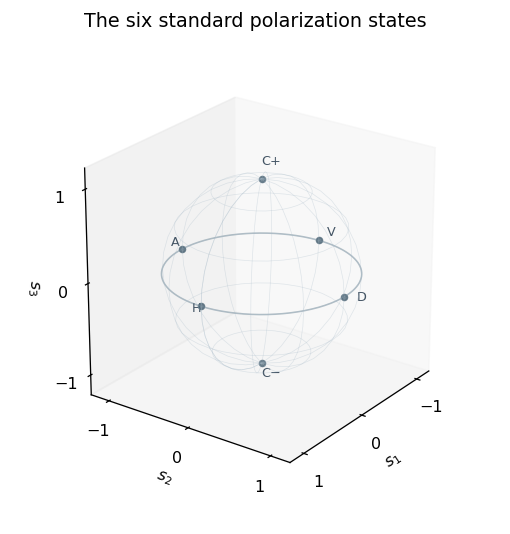

H (horizontal)        Stokes = [1. 1. 0. 0.]
V (vertical)          Stokes = [ 1. -1.  0.  0.]
D (+45°)              Stokes = [1. 0. 1. 0.]
A (−45°)              Stokes = [ 1.  0. -1.  0.]
C+ (s₃=+1)            Stokes = [1. 0. 0. 1.]
C− (s₃=−1)            Stokes = [ 1.  0.  0. -1.]


In [ ]:
# @title
fig = plt.figure(figsize=(6.9,5.5))
ax = fig.add_subplot(111, projection="3d")
sphere_axis(ax)
ax.set_title("The six standard polarization states")
plt.show()
for name in list(STATES)[:6]:
    print(f"{name:<20s}  Stokes = {np.array2string(stokes(STATES[name]), precision=2)}")


### **Experiment 3: Exploring the Poincaré sphere**

In this experiment, we revisit the polarization states explored in Experiment 1, now using the **Stokes parameters and the Poincaré sphere**.

Use the amplitude and relative-phase sliders to modify the polarization state. Observe how the polarization ellipse corresponds to a point on the sphere and how its Stokes parameters change.

The **degree of polarization (DoP)** slider allows you to introduce an unpolarized contribution while keeping the total intensity constant. The left plot shows the reference fully polarized field, while the right plot shows its location on the sphere and the resulting partially polarized state.

**Explore:**

- Locate the horizontal, vertical, diagonal, and circular polarization states on the sphere.
- Observe how changing the relative phase moves the state across the sphere.
- Reduce the degree of polarization. What happens to the position of the Stokes vector?


In [ ]:

# @title
def show_poincare_experiment(amplitude_angle, relative_phase, dop):

    a = np.deg2rad(amplitude_angle)
    d = np.deg2rad(relative_phase)

    # Reference fully polarized Jones state
    E = normalize([
        np.cos(a),
        np.sin(a) * np.exp(1j*d)
    ])

    # Fully polarized and partially polarized Stokes vectors
    S_ref = stokes(E)
    rho = coherency(E, dop=dop)
    S = stokes_rho(rho)

    s_ref = S_ref[1:] / S_ref[0]
    s = S[1:] / S[0]

    fig = plt.figure(figsize=(11, 4.8))

    # Left: reference polarization ellipse
    ax1 = fig.add_subplot(1, 2, 1)
    ellipse_axis(
        ax1, E,
        "Reference polarization ellipse",
        color="#287b83"
    )

    # Right: Poincare sphere
    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    sphere_axis(ax2)

    # Radial line illustrates the degree of polarization
    ax2.plot(
        [0, s_ref[0]],
        [0, s_ref[1]],
        [0, s_ref[2]],
        color="#d94f41", lw=1.5, alpha=.45
    )

    # Resulting state (may be inside the sphere)
    ax2.scatter(
        *s, color="#d94f41", s=85,
        depthshade=False, label="Resulting state"
    )

    # Reference fully polarized state
    ax2.scatter(
        *s_ref, marker="x", color="#263e54",
        s=90, linewidths=2.2,
        depthshade=False, label="Reference state"
    )

    ax2.set_title("Poincaré sphere", pad=12)
    ax2.legend(loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.show()

    # Ellipse angles of the reference fully polarized state
    psi = .5 * np.rad2deg(np.arctan2(s_ref[1], s_ref[0]))
    chi = .5 * np.rad2deg(np.arcsin(np.clip(s_ref[2], -1, 1)))

    psi_text = (
        "undefined (circular)"
        if np.hypot(s_ref[0], s_ref[1]) < 1e-8
        else f"{psi:.1f}°"
    )

    print("Stokes vector [S0, S1, S2, S3]:",
          np.round(S, 3))
    print("Normalized Stokes vector [s1, s2, s3]:",
          np.round(s, 3))
    print(f"Degree of polarization: {dop:.2f}")
    print(f"Reference ellipse: ψ = {psi_text}, χ = {chi:.1f}°")


# Interactive sliders
_p_amp = widgets.FloatSlider(
    value=30, min=0, max=90, step=2.5,
    description="Amplitude θ (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_p_phase = widgets.FloatSlider(
    value=60, min=-180, max=180, step=5,
    description="Relative phase δ (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_p_dop = widgets.FloatSlider(
    value=1, min=0, max=1, step=.05,
    description="Degree of polarization",
    continuous_update=False,
    style={"description_width": "initial"}
)

_p_out = widgets.interactive_output(
    show_poincare_experiment,
    {
        "amplitude_angle": _p_amp,
        "relative_phase": _p_phase,
        "dop": _p_dop
    }
)

display(widgets.VBox([
    _p_amp, _p_phase, _p_dop, _p_out
]))



### **Checkpoint 3: Understanding Stokes parameters and the Poincaré sphere**

**1. Representing polarization states**

Identify the positions of the following polarization states on the Poincaré sphere:

- Horizontal and vertical polarization.
- Diagonal and antidiagonal polarization.
- The two circular polarization states.

What relationship do you observe between each pair?

**2. Polarization ellipse and Poincaré sphere**

Choose an elliptically polarized state and change the sign of its relative phase, $\delta\rightarrow-\delta$.

- How does the polarization ellipse change?
- Which Stokes parameters remain unchanged?
- How is this transformation represented on the Poincaré sphere?

**3. Orientation and ellipticity**

Explore how the orientation angle $\psi$ and ellipticity angle $\chi$ relate to the position of a state on the sphere.

- What happens to the Stokes parameters when the orientation of a linearly polarized state changes by $45^\circ$?
- Is the orientation angle $\psi$ always well-defined?
- What values of $\chi$ correspond to linear and circular polarization?

**4. Degree of polarization**

Choose a polarization state and gradually reduce its degree of polarization.

- What happens to its normalized Stokes vector?
- What happens when the DoP reaches zero?
- Can the resulting partially polarized state be described by a single Jones vector? Explain.


## **4. Polarization transformations on the Poincaré sphere**

In the previous sections, we described how waveplates modify polarization using Jones matrices. These transformations also have a simple geometrical interpretation: **an ideal lossless retarder rotates the polarization state on the Poincaré sphere**.

### **4.1 Geometrical interpretation of waveplates**

For a linear retarder, the rotation occurs around an axis connecting two antipodal points on the equator of the Poincaré sphere. These points correspond to the orthogonal linear polarization states aligned with the principal axes of the retarder.

These principal axes are commonly referred to as the **fast and slow axes**. The fast axis corresponds to the direction along which light experiences a smaller phase delay, while the slow axis corresponds to the perpendicular direction, where the phase delay is larger. Light polarized along either axis preserves its polarization state after passing through the waveplate.

Let $\theta$ denote the orientation of the **slow axis** relative to the horizontal direction. The corresponding rotation axis on the Poincaré sphere is

$$
\hat{\mathbf n}=
\begin{pmatrix}
\cos(2\theta)\\
\sin(2\theta)\\
0
\end{pmatrix}.
$$

The factor of two arises because a linear polarization oriented at an angle $\theta$ is represented at an azimuthal angle $2\theta$ on the Poincaré sphere. Consequently, rotating the waveplate by $45^\circ$ rotates the direction of its axis on the sphere by $90^\circ$.

Since the fast and slow axes are perpendicular, they correspond to **opposite ends of the same diameter** on the Poincaré sphere.

The angle of rotation on the sphere is determined by the retardance $\Delta$. Using our Jones-matrix and Stokes conventions, the transformation corresponds to a rotation by $-\Delta$ about the slow-axis direction $\hat{\mathbf n}$, or equivalently by $+\Delta$ about the opposite, fast-axis direction.

Consequently, two important cases are:

- **Quarter-wave plate (QWP):** Produces a rotation of $90^\circ$ on the Poincaré sphere.
- **Half-wave plate (HWP):** Produces a rotation of $180^\circ$ on the Poincaré sphere.

By changing the orientation of the waveplate, we change its rotation axis and therefore the resulting polarization state. For a fixed orientation, the polarization evolves along a circular arc around that axis as retardance accumulates.

### **4.2 Controlling polarization with waveplates**

We will first explore how rotating an individual QWP or HWP modifies the position of a polarization state on the Poincaré sphere. In this case, the retardance remains fixed while the rotation axis changes with the waveplate orientation.

An individual waveplate can produce a variety of transformations, but its action is constrained by its fixed retardance.

**By combining waveplates with independently adjustable orientations, we gain greater control over the polarization state.**

In particular, we will investigate a sequence of three waveplates,

$$
\boxed{\mathrm{QWP}_1\ \longrightarrow\ \mathrm{HWP}\ \longrightarrow\ \mathrm{QWP}_2,}
$$

whose combined Jones transformation is

$$
\mathbf e_{\mathrm{out}}
=
QWP(\theta_3)\,HWP(\theta_2)\,QWP(\theta_1)
\,\mathbf e_{\mathrm{in}}.
$$

Each waveplate rotates the polarization state around an orientation-dependent axis on the Poincaré sphere. By adjusting their orientations, we can control the successive transformations and, with suitable settings, **transform a given fully polarized input into any desired fully polarized output state**.

This provides a geometrical understanding of how a sequence of simple optical elements can act as a general polarization controller.


### **Experiment 4.1: Rotations on the Poincaré sphere**

In this experiment, we explore the geometrical action of a single waveplate on the Poincaré sphere.

Choose an input polarization state, select either a **quarter-wave plate (QWP)** or a **half-wave plate (HWP)**, and vary the orientation of its **fast axis**.

The middle panel shows the optical element and its fast axis. The Poincaré-sphere panel shows the **input state**, the **current output state**, and the **trajectory traced by the output state** as the fast-axis angle is varied. The dashed diameter indicates the rotation axis associated with the waveplate.

**Explore:**
- How does the trajectory depend on whether the element is a QWP or a HWP?
- What happens when the input state is aligned with one of the principal axes?
- How does the output polarization ellipse change as the fast axis rotates?
- Which trajectories remain on the equator, and which leave it?

In [ ]:
# @title
from matplotlib.patches import Circle, FancyBboxPatch

def apply_waveplate_from_fast_axis(Ein, element, fast_axis_deg):
    """
    The slider controls the FAST axis.
    The retarder(theta, delta) function uses theta for the first principal axis.
    With the present convention, for positive retardance this corresponds to the slow axis,
    so we convert:
        slow axis = fast axis - 90 degrees
    """
    slow_axis_deg = fast_axis_deg - 90.0
    U = QWP(slow_axis_deg) if element == "Quarter-wave plate" else HWP(slow_axis_deg)
    return normalize(U @ Ein), U

def draw_mounted_waveplate(ax, element, fast_axis_deg):
    setup_waveplate_panel(ax)
    draw_waveplate_mount(ax, 0, .10, 1.0, fast_axis_deg, element)
    ax.set_title("Optical element", pad=10)


def show_waveplate_trajectory(initial, element, fast_axis_deg):
    Ein = STATES[initial]
    Eout, U = apply_waveplate_from_fast_axis(Ein, element, fast_axis_deg)

    # Current Stokes vectors
    S_in = stokes(Ein)
    S_out = stokes(Eout)
    s_in = S_in[1:] / S_in[0]
    s_out = S_out[1:] / S_out[0]

    # Trajectory by sweeping fast axis
    angs = np.linspace(-90, 90, 361)
    traj = []
    for ang in angs:
        Etmp, _ = apply_waveplate_from_fast_axis(Ein, element, ang)
        S = stokes(Etmp)
        traj.append(S[1:] / S[0])
    traj = np.array(traj)

    # Rotation axis on the Poincaré sphere
    alpha = np.deg2rad(fast_axis_deg)
    n_fast = np.array([np.cos(2*alpha), np.sin(2*alpha), 0.0])

    fig = plt.figure(figsize=(18, 4.8), constrained_layout=True)
    gs = fig.add_gridspec(1, 4, width_ratios=[1.0, 1.05, 1.35, 1.0])

    # Panel 1: input ellipse
    ax0 = fig.add_subplot(gs[0, 0])
    ellipse_axis(ax0, Ein, "Input polarization state", color="#788da0")

    # Panel 2: mounted optic
    ax1 = fig.add_subplot(gs[0, 1])
    draw_mounted_waveplate(ax1, element, fast_axis_deg)

    # Panel 3: Poincare sphere
    ax2 = fig.add_subplot(gs[0, 2], projection="3d")
    sphere_axis(ax2)

    # Rotation axis
    ax2.plot(
        [-n_fast[0], n_fast[0]],
        [-n_fast[1], n_fast[1]],
        [0, 0],
        color="#4b4b4b", lw=1.6, ls="--", alpha=0.85
    )
    ax2.scatter(*n_fast, color="#f2d34f", edgecolor="k", s=55, depthshade=False)
    ax2.text(*(1.12*n_fast), "F", fontsize=9, color="#222222")

    # Input and output states
    ax2.scatter(*s_in, c="#788da0", s=60, depthshade=False, label="input")
    ax2.scatter(*s_out, c="#d94f41", s=85, depthshade=False, label="current output")

    # Full trajectory
    ax2.plot(traj[:, 0], traj[:, 1], traj[:, 2], color="#2a9aa4", lw=2.5, alpha=0.95)

    ax2.set_title("Poincaré-sphere trajectory", pad=12)
    ax2.legend(loc="upper left", fontsize=8)

    # Panel 4: output ellipse
    ax3 = fig.add_subplot(gs[0, 3])
    ellipse_axis(ax3, Eout, "Output polarization state", color="#287b83")

    plt.show()

    print(f"Input state: {initial}")
    print(f"Element: {element}")
    print(f"Fast axis: {fast_axis_deg:.1f}°")
    print("Input normalized Stokes vector [s1,s2,s3]:", np.round(s_in, 3))
    print("Output normalized Stokes vector [s1,s2,s3]:", np.round(s_out, 3))
    print("Jones matrix (rounded):\n", np.round(U, 3))

# Interactive controls
_exp4_input = widgets.Dropdown(
    options=list(STATES),
    value="D (+45°)",
    description="Input",
    style={"description_width": "initial"}
)

_exp4_element = widgets.Dropdown(
    options=["Quarter-wave plate", "Half-wave plate"],
    value="Quarter-wave plate",
    description="Waveplate",
    style={"description_width": "initial"}
)

_exp4_axis = widgets.FloatSlider(
    value=-90,
    min=-90,
    max=90,
    step=2.5,
    description="Fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_exp4_out = widgets.interactive_output(
    show_waveplate_trajectory,
    {
        "initial": _exp4_input,
        "element": _exp4_element,
        "fast_axis_deg": _exp4_axis
    }
)

display(widgets.VBox([
    widgets.HBox([_exp4_input, _exp4_element]),
    _exp4_axis,
    _exp4_out
]))

 ### **Experiment 4.2: General polarization control**

In the previous experiment, we explored how a single waveplate transforms polarization through rotations on the Poincaré sphere. By combining multiple waveplates, we can perform more general transformations and **gain complete control over the polarization state**.

Consider a sequence of three waveplates:

$$
\mathrm{QWP}_1 \longrightarrow \mathrm{HWP}
\longrightarrow \mathrm{QWP}_2.
$$

The combined Jones transformation is

$$
\mathbf{e}_{\mathrm{out}} =
QWP(\theta_3)\,HWP(\theta_2)\,QWP(\theta_1)
\mathbf{e}_{\mathrm{in}},
$$

where $\theta_1$, $\theta_2$, and $\theta_3$ represent the orientations of the waveplates.

Each element introduces a rotation around a different axis on the Poincaré sphere. By independently adjusting their orientations, we can control the successive transformations and **reach any desired fully polarized output state** from a given fully polarized input.

**Use the interactive sliders** to modify the fast-axis orientation of each waveplate. Observe the input, intermediate, and output polarization states, together with their evolution on the Poincaré sphere.

The colored trajectories represent the evolution of the polarization state as retardance accumulates through each waveplate at its selected orientation.


In [ ]:

# @title Experiment 4.2: QWP-HWP-QWP polarization controller

from matplotlib.patches import Circle, FancyArrowPatch

# ---------- Polarization transformations ----------

def qhq_states(Ein, theta1, theta2, theta3):
    """Calculate successive Jones states and Poincare trajectories."""

    plates = [
        (theta1, np.pi/2),
        (theta2, np.pi),
        (theta3, np.pi/2)
    ]

    states = [normalize(Ein)]
    trajectories = []

    for fast_axis, delta in plates:
        # Convert fast-axis orientation to the first (slow) axis
        # used by our retarder() convention.
        slow_axis = fast_axis - 90

        E_before = states[-1]
        path = []

        # Continuous evolution as retardance accumulates
        for phase in np.linspace(0, delta, 100):
            E = normalize(retarder(slow_axis, phase) @ E_before)
            S = stokes(E)
            path.append(S[1:] / S[0])

        trajectories.append(np.array(path))

        E_after = normalize(retarder(slow_axis, delta) @ E_before)
        states.append(E_after)

    return states, trajectories


# ---------- Optical setup illustration ----------

def draw_qhq_setup(ax, angles):
    ax.set_xlim(-1, 11)
    ax.set_ylim(-.88, .85)
    ax.set_aspect("equal")
    ax.axis("off")

    for x, angle, kind, label in zip(
        [1.3, 5.0, 8.7], angles,
        ["QWP", "HWP", "QWP"],
        ["QWP₁", "HWP", "QWP₂"]
    ):
        draw_waveplate_mount(
            ax, x, 0, .49, angle, kind, label=label
        )

    # Fixed beam-path arrows, separate from rotation mounts
    for xa, xb in [
        (-.5, .7), (1.83, 4.43), (5.55, 8.13), (9.23, 10.5)
    ]:
        ax.add_patch(FancyArrowPatch(
            (xa, 0), (xb, 0),
            arrowstyle="-|>", mutation_scale=15,
            linewidth=1.5, color="#758a9a"
        ))


# ---------- Interactive visualization ----------

def show_qhq_experiment(initial, theta1, theta2, theta3,
                        show_axes):

    states, trajectories = qhq_states(
        STATES[initial], theta1, theta2, theta3
    )

    points = np.array([
        stokes(E)[1:] / stokes(E)[0] for E in states
    ])

    colors = [
        "#788da0",  # Input
        "#2499a3",  # After QWP1
        "#dc8c39",  # After HWP
        "#ad4b87"   # After QWP2
    ]

    labels = [
        "Input",
        "After QWP₁",
        "After HWP",
        "After QWP₂"
    ]

    fig = plt.figure(figsize=(13.5, 8))

    main = fig.add_gridspec(
        2, 1,
        height_ratios=[1.1, 5.8],
        left=.035, right=.97,
        bottom=.08, top=.96,
        hspace=.13
    )

    # Optical arrangement
    ax_setup = fig.add_subplot(main[0])
    draw_qhq_setup(ax_setup, (theta1, theta2, theta3))

    # Sphere and four polarization ellipses
    gs = main[1].subgridspec(
        2, 3,
        width_ratios=[1.65, 1, 1],
        wspace=.38,
        hspace=.57
    )

    ax = fig.add_subplot(gs[:, 0], projection="3d")
    sphere_axis(ax)

    # Trajectories through individual waveplates
    for path, color, label in zip(
        trajectories, colors[1:], labels[1:]
    ):
        ax.plot(
            path[:, 0], path[:, 1], path[:, 2],
            color=color, lw=2.8,
            alpha=.96, label=label
        )

    # Input, intermediate, and output states
    for i, (point, color) in enumerate(zip(points, colors)):
        ax.scatter(
            *point,
            s=90 if i == 3 else 55,
            c=color,
            depthshade=False,
            edgecolor="white",
            linewidth=.5
        )

    # Optional Poincare rotation axes
    if show_axes:
        for angle, color in zip(
            (theta1, theta2, theta3), colors[1:]
        ):
            t = np.deg2rad(2*angle)
            n = np.array([np.cos(t), np.sin(t), 0.])

            ax.plot(
                [-n[0], n[0]],
                [-n[1], n[1]],
                [0, 0],
                ls="--", alpha=.55,
                lw=1.2, color=color
            )

    ax.set_title("Poincaré-sphere evolution", pad=16)
    ax.legend(
        loc="upper left",
        fontsize=8,
        frameon=False
    )

    # Four polarization ellipses
    positions = [
        (0, 1), (0, 2),
        (1, 1), (1, 2)
    ]

    for i, (row, col) in enumerate(positions):
        a = fig.add_subplot(gs[row, col])
        ellipse_axis(
            a, states[i], labels[i],
            color=colors[i]
        )

    plt.show()

    # Numerical results
    print("Input:", initial)
    print("-" * 53)

    for label, E in zip(labels, states):
        S = stokes(E)
        print(f"{label:12s}  S = {np.round(S, 3)}")

    print("\nFinal Jones vector:", np.round(states[-1], 3))


# ---------- Interactive controls ----------

_q42_input = widgets.Dropdown(
    options=list(STATES),
    value="H (horizontal)",
    description="Input"
)

_q42_angle1 = widgets.FloatSlider(
    value=45, min=-90, max=90, step=2.5,
    description="QWP₁ fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_q42_angle2 = widgets.FloatSlider(
    value=22.5, min=-90, max=90, step=2.5,
    description="HWP fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_q42_angle3 = widgets.FloatSlider(
    value=0, min=-90, max=90, step=2.5,
    description="QWP₂ fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_q42_axes = widgets.Checkbox(
    value=False,
    description="Show waveplate rotation axes"
)

_q42_out = widgets.interactive_output(
    show_qhq_experiment,
    {
        "initial": _q42_input,
        "theta1": _q42_angle1,
        "theta2": _q42_angle2,
        "theta3": _q42_angle3,
        "show_axes": _q42_axes
    }
)

display(widgets.VBox([
    _q42_input,
    _q42_angle1,
    _q42_angle2,
    _q42_angle3,
    _q42_axes,
    _q42_out
]))


### **Checkpoint 4.2: Controlling polarization**

**1. Reaching a target polarization**

Starting from horizontally polarized light, find waveplate orientations that produce each of the following output states:

- Vertical linear polarization.
- Diagonal linear polarization at $+45^\circ$.
- Circular polarization $C+$ and $C-$.

Can you find more than one configuration for each target state?

**2. Successive transformations**

Choose a configuration in which the first QWP produces circular polarization.

- How does changing the orientation of the HWP affect the polarization?
- Can the second QWP transform the resulting state back into linear polarization?

**3. Different transformations, same output**

Find two different sets of waveplate orientations that produce the same output polarization.

Do the corresponding Jones matrices have to be identical? Explain.

**4. Controlling the trajectory**

Keep two waveplates fixed and vary the orientation of the remaining one.

- How does the trajectory on the Poincaré sphere change?
- Does changing the first QWP have the same effect as changing the last QWP? Why or why not?


## **5. Stokes polarimetry: measuring polarization**

So far, we have described polarization states and predicted their transformations through optical elements. However, in the laboratory, the polarization of an incident beam may be unknown. **How can we determine its polarization state experimentally?**

Optical detectors typically measure intensity rather than the complex electric-field amplitudes. Fortunately, the Stokes parameters can be reconstructed from a series of intensity measurements performed using different polarization analyzers. This procedure is known as **Stokes polarimetry**.

### 5.1 Measuring the Stokes parameters

Consider an incident beam with an unknown polarization state. By measuring the intensity transmitted through different polarization analyzers, we can determine how much of the incident light is associated with each polarization component.

Six particularly useful measurements are:

| Measurement | Polarization analyzed |
|---|---|
| $I_H$ | Horizontal |
| $I_V$ | Vertical |
| $I_D$ | Diagonal ($+45^\circ$) |
| $I_A$ | Antidiagonal ($-45^\circ$) |
| $I_{C+}$ | Positive circular |
| $I_{C-}$ | Negative circular |

The Stokes parameters can then be reconstructed from the differences between complementary intensity measurements:

$$
\boxed{
\begin{aligned}
S_0 &= I_H+I_V = I_D+I_A = I_{C+}+I_{C-},\\
S_1 &= I_H-I_V,\\
S_2 &= I_D-I_A,\\
S_3 &= I_{C+}-I_{C-}.
\end{aligned}
}
$$

Notice that **each Stokes parameter describes an intensity difference between two orthogonal polarization states**, while $S_0$ corresponds to the total intensity.

Although only four independent intensity measurements are required in an ideal system, using six measurements provides a convenient and symmetric method, with redundant estimates of the total intensity.

Once the Stokes parameters have been reconstructed, we can calculate the normalized Stokes vector and locate the measured polarization state on the Poincaré sphere.



### **Experiment 5.1: Reconstructing the Stokes parameters**

In this experiment, we simulate the six intensity measurements required to characterize an unknown polarization state.

Choose an input polarization state and observe the intensity associated with each of the six polarization projections. The reconstructed Stokes vector is displayed on the Poincaré sphere.

Use the **degree of polarization (DoP)** slider to investigate how the measurements change when an unpolarized contribution is added to the beam.

**Explore:**

- How do the six intensities change for horizontal, diagonal, and circular polarization?
- Which measurements contain information about the orientation of linear polarization?
- Which measurements distinguish between the two circular polarization states?
- What happens to the measured intensities when the DoP decreases?


In [ ]:

# @title
from IPython.display import Markdown

# Six polarization analysis states
_POL_BASIS = {
    "H":  STATES["H (horizontal)"],
    "V":  STATES["V (vertical)"],
    "D":  STATES["D (+45°)"],
    "A":  STATES["A (−45°)"],
    "C+": STATES["C+ (s₃=+1)"],
    "C-": STATES["C− (s₃=−1)"]
}

_POL_LABELS = list(_POL_BASIS)


def six_measurements(rho):
    """Intensity projected onto each polarization basis state."""
    return {
        name: float(np.real(np.vdot(e, rho @ e)))
        for name, e in _POL_BASIS.items()
    }


def reconstruct_stokes(I):
    """Reconstruct the Stokes vector from six intensities."""
    S0 = (
        I["H"] + I["V"]
        + I["D"] + I["A"]
        + I["C+"] + I["C-"]
    ) / 3

    return np.array([
        S0,
        I["H"] - I["V"],
        I["D"] - I["A"],
        I["C+"] - I["C-"]
    ])


def show_six_measurements(initial, dop):

    rho = coherency(STATES[initial], dop=dop)

    # Simulated measurements
    I = six_measurements(rho)
    S = reconstruct_stokes(I)
    s = S[1:] / S[0]

    fig = plt.figure(figsize=(11, 4.8))

    # Measured intensities
    ax0 = fig.add_subplot(1, 2, 1)

    values = [I[k] for k in _POL_LABELS]

    ax0.bar(
        _POL_LABELS, values,
        color=["#728ca1", "#728ca1",
               "#3199a5", "#3199a5",
               "#d68c3f", "#d68c3f"],
        edgecolor="white"
    )

    ax0.set(
        ylim=(0, 1.05),
        ylabel="Normalized measured intensity",
        xlabel="Polarization analyzed",
        title="Six intensity measurements"
    )
    ax0.grid(axis="y", alpha=.2)

    # Reconstructed state on Poincare sphere
    ax1 = fig.add_subplot(1, 2, 2, projection="3d")
    sphere_axis(ax1)

    ax1.plot(
        [0, s[0]], [0, s[1]], [0, s[2]],
        color="#d94f41", lw=2
    )

    ax1.scatter(
        *s, color="#d94f41",
        s=90, depthshade=False
    )

    ax1.set_title("Reconstructed polarization", pad=12)

    fig.subplots_adjust(wspace=.3)
    plt.show()

    display(Markdown(
        f"**Reconstructed Stokes vector:** "
        f"`{np.round(S, 3)}`  \n"
        f"**Degree of polarization:** "
        f"{np.linalg.norm(S[1:])/S[0]:.3f}"
    ))


_p51_input = widgets.Dropdown(
    options=list(STATES),
    value="Elliptical example",
    description="Input",
    style={"description_width": "initial"}
)

_p51_dop = widgets.FloatSlider(
    value=1, min=0, max=1, step=.05,
    description="DoP",
    continuous_update=False
)

_p51_out = widgets.interactive_output(
    show_six_measurements,
    {"initial": _p51_input, "dop": _p51_dop}
)

display(widgets.VBox([
    _p51_input,
    _p51_dop,
    _p51_out
]))



### **5.2 Stokes polarimetry with a single detector**

The six polarization measurements can be performed using a linear polarizer and a quarter-wave plate. In a laboratory, a **polarizing beam splitter (PBS)** can also be used as a polarization analyzer.

Consider the following arrangement:

$$
\boxed{
\mathrm{HWP}
\longrightarrow
\mathrm{QWP}
\longrightarrow
\mathrm{PBS}
\longrightarrow
\mathrm{Detector}
}
$$

The HWP and QWP transform the incident polarization, while the PBS separates the horizontal and vertical components. By measuring the intensity at one output of the PBS and changing the waveplate orientations, we can reconstruct the Stokes parameters without needing a second detector.

For a fully polarized incident field, the measured intensity is proportional to

$$
I(h,q)=
\left\|
P_H J_{\mathrm{QWP}}(q)
J_{\mathrm{HWP}}(h)
\mathbf{e}_{\mathrm{in}}
\right\|^2,
$$

where $h$ and $q$ are the fast-axis orientations of the HWP and QWP, respectively, and $P_H$ selects the horizontal output of the PBS.

#### Six measurement configurations

Using our Jones-matrix conventions, the following fast-axis orientations produce the six polarization projections:

| Measurement | HWP fast axis | QWP fast axis |
|---|---:|---:|
| $I_H$ | $0^\circ$ | $0^\circ$ |
| $I_V$ | $45^\circ$ | $0^\circ$ |
| $I_D$ | $22.5^\circ$ | $0^\circ$ |
| $I_A$ | $-22.5^\circ$ | $0^\circ$ |
| $I_{C+}$ | $0^\circ$ | $-45^\circ$ |
| $I_{C-}$ | $0^\circ$ | $45^\circ$ |

These orientations assume that the detector measures the **horizontal PBS output**. Selecting the other output, changing the order of the waveplates, or using a different retardance convention may require different settings.

In practice, the six intensities are recorded sequentially. Therefore, the incident intensity should remain stable during the measurement.


In [ ]:

# @title

# Fast-axis angles in degrees: (HWP, QWP)
_POL_SETTINGS = {
    "H":  (0, 0),
    "V":  (45, 0),
    "D":  (22.5, 0),
    "A":  (-22.5, 0),
    "C+": (0, -45),
    "C-": (0, 45)
}


def analyzer_matrix(h_fast, q_fast):
    """
    HWP -> QWP -> horizontal PBS output.
    Convert fast-axis angles to the first (slow) axis
    used by the notebook's retarder() function.
    """
    return QWP(q_fast - 90) @ HWP(h_fast - 90)


def single_port_intensity(rho, h_fast, q_fast):
    """Intensity measured at the horizontal PBS output."""
    U = analyzer_matrix(h_fast, q_fast)
    rho_out = U @ rho @ U.conj().T
    return float(np.real(rho_out[0, 0]))


def show_single_detector(initial, dop, h_fast, q_fast):

    rho = coherency(STATES[initial], dop=dop)

    # Detector reading for the current slider settings
    measured = single_port_intensity(rho, h_fast, q_fast)

    # Simulated full six-setting scan
    intensities = {
        name: single_port_intensity(rho, *angles)
        for name, angles in _POL_SETTINGS.items()
    }

    S = reconstruct_stokes(intensities)
    s = S[1:] / S[0]

    # State transmitted with unit probability by the
    # current analyzer, for fully polarized matching input
    U = analyzer_matrix(h_fast, q_fast)
    analyzer_state = normalize(
        U.conj().T @ np.array([1, 0], complex)
    )
    Sa = stokes(analyzer_state)
    sa = Sa[1:] / Sa[0]

    fig = plt.figure(figsize=(13.5, 4.6))

    gs = fig.add_gridspec(
        1, 3,
        width_ratios=[1, 1.5, 1.35],
        left=.06, right=.97,
        bottom=.17, top=.83,
        wspace=.40
    )

    # Current detector reading
    ax0 = fig.add_subplot(gs[0, 0])

    ax0.barh(
        [0], [measured],
        color="#d68c3f", height=.35
    )

    ax0.set(
        xlim=(0, 1.05),
        ylim=(-.7, .7),
        xlabel="Normalized intensity",
        title="Single detector"
    )

    ax0.set_yticks([])
    ax0.grid(axis="x", alpha=.2)

    ax0.text(
        .5, .82, f"I = {measured:.3f}",
        transform=ax0.transAxes,
        ha="center", fontsize=13, fontweight="bold"
    )

    # Full six-setting scan
    ax1 = fig.add_subplot(gs[0, 1])

    ax1.bar(
        list(intensities),
        list(intensities.values()),
        color="#3199a5"
    )

    ax1.set(
        ylim=(0, 1.05),
        ylabel="Normalized intensity",
        title="Complete six-setting scan"
    )
    ax1.grid(axis="y", alpha=.2)

    # Reconstructed state and current analyzer state
    ax2 = fig.add_subplot(gs[0, 2], projection="3d")
    sphere_axis(ax2)

    ax2.scatter(
        *s, color="#d94f41",
        s=90, depthshade=False,
        label="Reconstructed"
    )

    ax2.scatter(
        *sa, color="#8d59ad",
        marker="x", linewidths=2,
        s=90, depthshade=False,
        label="Current analyzer"
    )

    ax2.set_title("Poincaré sphere", pad=12)
    ax2.legend(loc="upper left", fontsize=8)

    fig.suptitle(
        "Unknown beam → HWP → QWP → PBS (H output) → Detector",
        fontsize=12, y=.97
    )

    plt.show()

    display(Markdown(
        f"**Current fast-axis settings:** "
        f"HWP = {h_fast:.1f}°, QWP = {q_fast:.1f}°  \n"
        f"**Detector intensity:** {measured:.3f}  \n"
        f"**Reconstructed Stokes vector:** "
        f"`{np.round(S, 3)}`  \n"
        f"**DoP:** {np.linalg.norm(S[1:])/S[0]:.3f}"
    ))


# ---------- Interactive controls ----------

_lab_input = widgets.Dropdown(
    options=list(STATES),
    value="Elliptical example",
    description="Input"
)

_lab_dop = widgets.FloatSlider(
    value=1, min=0, max=1, step=.05,
    description="DoP",
    continuous_update=False
)

_lab_h = widgets.FloatSlider(
    value=0, min=-90, max=90, step=2.5,
    description="HWP fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_lab_q = widgets.FloatSlider(
    value=-45, min=-90, max=90, step=2.5,
    description="QWP fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"}
)

_lab_preset = widgets.Dropdown(
    options=list(_POL_SETTINGS),
    value="C+",
    description="Analyzer preset"
)

_lab_apply = widgets.Button(
    description="Apply preset",
    button_style="info",
    icon="check"
)

def apply_preset(button):
    h, q = _POL_SETTINGS[_lab_preset.value]
    _lab_h.value = h
    _lab_q.value = q

_lab_apply.on_click(apply_preset)

_lab_out = widgets.interactive_output(
    show_single_detector,
    {
        "initial": _lab_input,
        "dop": _lab_dop,
        "h_fast": _lab_h,
        "q_fast": _lab_q
    }
)

display(widgets.VBox([
    widgets.HBox([_lab_input, _lab_dop]),
    widgets.HBox([_lab_preset, _lab_apply]),
    _lab_h,
    _lab_q,
    _lab_out
]))



### **Checkpoint 5: Understanding Stokes polarimetry**

**1. Reconstructing the Stokes parameters**

For an unknown beam, the following normalized intensities are measured:

$$
\begin{aligned}
I_H &= 0.7, & I_V &= 0.3,\\
I_D &= 0.6, & I_A &= 0.4,\\
I_{C+} &= 0.8, & I_{C-} &= 0.2.
\end{aligned}
$$

Calculate the Stokes vector and the degree of polarization. Is the beam fully or partially polarized?

**2. Measuring circular polarization**

Why are measurements with a linear polarizer alone insufficient to determine the complete polarization state? What role does the QWP play?

**3. Using a single detector**

Explain how the HWP → QWP → PBS arrangement allows all four Stokes parameters to be reconstructed using only one detector.

**4. Laboratory considerations**

Suppose the incident beam intensity changes between successive measurements.

- How would this affect the reconstructed Stokes parameters?
- What could you do experimentally to reduce this error?

**5. Limitations of polarimetry**

Can a Stokes polarimeter determine the global phase of the incident electric field? Explain your answer.



## **6. Virtual laboratory: Measuring an unknown polarization state**

In the previous section, we learned how to reconstruct the Stokes parameters from intensity measurements. Now, we will apply this procedure to characterize an **unknown polarization state** using a virtual polarimeter.

The experimental arrangement consists of

$$
\boxed{
\text{Unknown input}
\;\longrightarrow\;
\mathrm{HWP}
\;\longrightarrow\;
\mathrm{QWP}
\;\longrightarrow\;
\mathrm{PBS}
\;\longrightarrow\;
\text{Detector}
}
$$

The polarization of the incident beam is randomly generated and remains hidden. Your goal is to determine its **Stokes parameters and degree of polarization** using only the measured intensities.

### Experiment 6: Measuring an unknown polarization

Use the two sliders to rotate the fast axes of the HWP and QWP. The detector measures the intensity transmitted through the horizontal output of the PBS.

For each analyzer configuration, record the corresponding intensity and use your measurements to reconstruct the Stokes vector.

The available measurement configurations are:

| Measurement | HWP fast axis | QWP fast axis |
|---|---:|---:|
| $I_H$ | $0^\circ$ | $0^\circ$ |
| $I_V$ | $45^\circ$ | $0^\circ$ |
| $I_D$ | $22.5^\circ$ | $0^\circ$ |
| $I_A$ | $-22.5^\circ$ | $0^\circ$ |
| $I_{C+}$ | $0^\circ$ | $-45^\circ$ |
| $I_{C-}$ | $0^\circ$ | $45^\circ$ |

**Your task:**

1. Generate an unknown polarization state.
2. Adjust the waveplates and record the six intensity measurements.
3. Calculate the Stokes parameters using the measured intensities.
4. Determine the degree of polarization and identify whether the incident beam is fully or partially polarized.
5. Submit your results to check your calculations.

The simulation assumes ideal optical components, a stable incident intensity normalized to $S_0=1$, and a noiseless detector. The displayed intensities are rounded to three decimal places.


In [ ]:

# @title Experiment 6: Virtual Stokes Polarimetry Laboratory

from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch
from IPython.display import display, clear_output

# ---------- Unknown polarization source ----------

_v6_rng = np.random.default_rng()

def _v6_generate_unknown():
    """Random fully or partially polarized state, S0 = 1."""
    e = normalize(
        _v6_rng.normal(size=2)
        + 1j * _v6_rng.normal(size=2)
    )
    dop = float(_v6_rng.choice([1.0, 0.85, 0.65]))
    return coherency(e, dop=dop)


_v6_state = {
    "rho": _v6_generate_unknown(),
    "readings": {},
    "attempted": False,
    "case": 1
}

# Six calibrated analyzer settings: HWP, QWP fast axes
_v6_settings = {
    "H":  (0, 0),
    "V":  (45, 0),
    "D":  (22.5, 0),
    "A":  (-22.5, 0),
    "C+": (0, -45),
    "C-": (0, 45)
}


def _v6_intensity(h, q):
    """HWP -> QWP -> horizontal PBS output."""
    U = QWP(q - 90) @ HWP(h - 90)
    rho = _v6_state["rho"]
    rho_out = U @ rho @ U.conj().T
    return float(np.clip(np.real(rho_out[0, 0]), 0, 1))


def _v6_setting_name(h, q):
    """Recognize calibrated settings, including equivalent axes."""
    def same_axis(a, b, period):
        difference = (a - b + period/2) % period - period/2
        return abs(difference) < 1e-6

    for name, (h0, q0) in _v6_settings.items():
        if same_axis(h, h0, 90) and same_axis(q, q0, 180):
            return name
    return None


# ---------- Optical setup visualization ----------

def _v6_draw_plate(ax, x, angle, label, color=None):
    """Use the same waveplate mount as Experiments 2, 4.1, and 4.2."""
    draw_waveplate_mount(
        ax, x, 0, .70, angle, label, label=label
    )


def _v6_draw_setup(h, q, intensity):

    fig = plt.figure(figsize=(13, 4.8))

    gs = fig.add_gridspec(
        2, 1, height_ratios=[3.0, 1.0],
        left=.07, right=.96,
        top=.94, bottom=.14,
        hspace=.55
    )

    ax = fig.add_subplot(gs[0])
    ax.set_xlim(-.8, 14.1)
    ax.set_ylim(-1.65, 1.55)
    ax.set_aspect("equal")
    ax.axis("off")

    # Unknown source
    ax.add_patch(Circle(
        (.35, 0), .47,
        facecolor="#e0e6ed", edgecolor="#788da0", lw=1.5
    ))
    ax.text(.35, 0, "?", fontsize=22,
            ha="center", va="center", color="#41596e")
    ax.text(.35, .90, "Unknown", ha="center", fontsize=10)

    # Rotatable waveplates
    _v6_draw_plate(ax, 3.1, h, "HWP", "#43a26d")
    _v6_draw_plate(ax, 6.25, q, "QWP", "#e89439")

    # PBS cube
    ax.add_patch(FancyBboxPatch(
        (8.90, -.56), 1.12, 1.12,
        boxstyle="round,pad=0.02,rounding_size=0.05",
        facecolor="#dcebf5", edgecolor="#547a91", lw=1.6
    ))

    ax.plot([8.94, 9.98], [.50, -.50],
            color="#4d91b5", lw=2)

    ax.text(9.46, .90, "PBS", ha="center",
            fontsize=11, fontweight="bold")

    # Unused vertical output
    ax.annotate(
        "", xy=(9.46, -1.35), xytext=(9.46, -.57),
        arrowprops=dict(
            arrowstyle="-|>", color="#9da8b1",
            lw=1.4, linestyle="dashed"
        )
    )
    ax.text(10.0, -1.21, "Unused port",
            fontsize=8, color="#89959f")

    # Detector
    ax.add_patch(FancyBboxPatch(
        (11.70, -.49), 1.55, .98,
        boxstyle="round,pad=0.03,rounding_size=0.1",
        facecolor="#526675", edgecolor="#303f49", lw=1.5
    ))

    ax.add_patch(Circle(
        (12.47, 0), .23,
        facecolor="#b5d8eb", edgecolor="#e6f4fb", lw=1.2
    ))

    ax.text(12.47, .83, "Detector",
            fontsize=11, ha="center", fontweight="bold")

    # Light propagation arrows
    for x0, x1 in [
        (.90, 2.30),
        (3.88, 5.45),
        (7.02, 8.84),
        (10.08, 11.63)
    ]:
        ax.add_patch(FancyArrowPatch(
            (x0, 0), (x1, 0),
            arrowstyle="-|>", mutation_scale=15,
            color="#69899c", lw=1.8
        ))

    # Intensity meter
    meter = fig.add_subplot(gs[1])

    meter.barh(
        [0], [intensity],
        height=.48, color="#d68c3f",
        edgecolor="#a46a30"
    )

    meter.set_xlim(0, 1.05)
    meter.set_ylim(-.55, .65)
    meter.set_yticks([])
    meter.set_xlabel("Normalized detected intensity")
    meter.grid(axis="x", alpha=.2)

    meter.text(
        .5, .95, f"Detector reading: {intensity:.3f}",
        ha="center", va="bottom",
        transform=meter.transAxes,
        fontsize=12, fontweight="bold"
    )

    plt.show()
    plt.close(fig)


# ---------- Student measurement interface ----------

_v6_h = widgets.FloatSlider(
    value=0, min=-90, max=90, step=2.5,
    description="HWP fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="430px")
)

_v6_q = widgets.FloatSlider(
    value=0, min=-90, max=90, step=2.5,
    description="QWP fast axis (°)",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="430px")
)

_v6_plot = widgets.Output()
_v6_table = widgets.HTML()
_v6_status = widgets.HTML()

_v6_record = widgets.Button(
    description="Record measurement",
    button_style="success",
    icon="save"
)

_v6_new = widgets.Button(
    description="New unknown state",
    button_style="warning",
    icon="refresh"
)


def _v6_update_table():
    rows = []

    for name, (h, q) in _v6_settings.items():
        value = _v6_state["readings"].get(name)
        reading = "—" if value is None else f"{value:.3f}"

        rows.append(
            f"<tr>"
            f"<td style='padding:5px 18px'>{name}</td>"
            f"<td style='padding:5px 18px'>{h:g}°</td>"
            f"<td style='padding:5px 18px'>{q:g}°</td>"
            f"<td style='padding:5px 18px'><b>{reading}</b></td>"
            f"</tr>"
        )

    _v6_table.value = (
        "<h4>Recorded measurements</h4>"
        "<table style='border-collapse:collapse'>"
        "<tr><th>Projection</th><th>HWP</th>"
        "<th>QWP</th><th>Intensity</th></tr>"
        + "".join(rows) +
        "</table>"
        f"<p>{len(_v6_state['readings'])}/6 "
        "measurements recorded</p>"
    )


def _v6_refresh(change=None):
    intensity = _v6_intensity(_v6_h.value, _v6_q.value)

    with _v6_plot:
        clear_output(wait=True)
        _v6_draw_setup(_v6_h.value, _v6_q.value, intensity)


def _v6_record_measurement(button):
    name = _v6_setting_name(_v6_h.value, _v6_q.value)

    if name is None:
        _v6_status.value = (
            "<b>Custom analyzer setting.</b> "
            "To record a Stokes measurement, use one of the "
            "six calibrated configurations."
        )
        return

    value = round(_v6_intensity(_v6_h.value, _v6_q.value), 3)
    _v6_state["readings"][name] = value

    _v6_status.value = (
        f"<b>Recorded I<sub>{name}</sub> = {value:.3f}</b>"
    )
    _v6_update_table()


def _v6_new_case(button):
    _v6_state["rho"] = _v6_generate_unknown()
    _v6_state["readings"] = {}
    _v6_state["attempted"] = False
    _v6_state["case"] += 1

    for widget in _v6_answers:
        widget.value = 0.0

    _v6_feedback.value = ""
    _v6_reveal.disabled = True

    _v6_h.value = 0
    _v6_q.value = 0

    _v6_status.value = (
        "<b>New unknown generated.</b> "
        "All previous measurements have been cleared."
    )

    _v6_update_table()
    _v6_refresh()


_v6_h.observe(_v6_refresh, names="value")
_v6_q.observe(_v6_refresh, names="value")
_v6_record.on_click(_v6_record_measurement)
_v6_new.on_click(_v6_new_case)


# ---------- Check the student's hand calculations ----------

_v6_answers = [
    widgets.FloatText(
        value=0, description=name,
        layout=widgets.Layout(width="145px"),
        style={"description_width": "45px"}
    )
    for name in ["S₀", "S₁", "S₂", "S₃", "DoP"]
]

_v6_check = widgets.Button(
    description="Check my calculations",
    button_style="info",
    icon="check"
)

_v6_reveal = widgets.Button(
    description="Show solution",
    disabled=True
)

_v6_feedback = widgets.HTML()


def _v6_expected_answer():
    I = _v6_state["readings"]

    S = np.array([
        (
            I["H"] + I["V"]
            + I["D"] + I["A"]
            + I["C+"] + I["C-"]
        ) / 3,
        I["H"] - I["V"],
        I["D"] - I["A"],
        I["C+"] - I["C-"]
    ])

    dop = min(1.0, np.linalg.norm(S[1:]) / S[0])
    return np.r_[S, dop]


def _v6_check_answer(button):
    if len(_v6_state["readings"]) < 6:
        _v6_feedback.value = (
            "<b>Record all six measurements before "
            "checking your answer.</b>"
        )
        return

    expected = _v6_expected_answer()
    submitted = np.array([w.value for w in _v6_answers])

    differences = np.abs(submitted - expected)
    correct = differences < np.array([.015]*4 + [.025])

    labels = ["S₀", "S₁", "S₂", "S₃", "DoP"]
    feedback = []

    for name, passed in zip(labels, correct):
        feedback.append(
            f"{name}: {'✓ Correct' if passed else '✗ Check again'}"
        )

    _v6_feedback.value = (
        "<b>" +
        ("All calculations are correct!" if all(correct)
         else "Review the indicated quantities.") +
        "</b><p>" + " &nbsp; | &nbsp; ".join(feedback) + "</p>"
    )

    _v6_state["attempted"] = True
    _v6_reveal.disabled = False


def _v6_show_solution(button):
    if not _v6_state["attempted"]:
        return

    answer = _v6_expected_answer()

    _v6_feedback.value = (
        "<b>Reference solution (from recorded measurements)</b>"
        "<p>Stokes vector: "
        f"({answer[0]:.3f}, {answer[1]:.3f}, "
        f"{answer[2]:.3f}, {answer[3]:.3f})</p>"
        f"<p>Degree of polarization: {answer[4]:.3f}</p>"
    )


_v6_check.on_click(_v6_check_answer)
_v6_reveal.on_click(_v6_show_solution)

# ---------- Display the laboratory ----------

display(widgets.VBox([
    widgets.HTML("<h3>Virtual Stokes polarimeter</h3>"),
    _v6_h,
    _v6_q,
    _v6_plot,
    widgets.HBox([_v6_record, _v6_new]),
    _v6_status,
    _v6_table,
    widgets.HTML("<h4>Enter your calculated results</h4>"),
    widgets.HBox(_v6_answers[:3]),
    widgets.HBox(_v6_answers[3:]),
    widgets.HBox([_v6_check, _v6_reveal]),
    _v6_feedback
]))

_v6_update_table()
_v6_refresh()


## **7. Mueller calculus and optical device characterization**

In Sections 5 and 6, we used different analyzer settings to determine the Stokes vector of an **unknown incident beam**. We now reverse the question: suppose the incident polarization is known, but an optical device has an **unknown polarization response**. How can we characterize the device, rather than just the beam?

### **7.1 From Stokes vectors to Mueller matrices**

Jones calculus represents the response of a deterministic optical element by a complex $2\times 2$ matrix:

$$
\mathbf e_{\mathrm{out}}=J\mathbf e_{\mathrm{in}}.
$$

A single Jones vector describes a fully polarized field, but not partially polarized or unpolarized light. For such states, we have already introduced the four experimentally measurable Stokes parameters.

A **Mueller matrix** is a real $4\times4$ matrix that acts on Stokes vectors:

$$
\boxed{\mathbf S_{\mathrm{out}}=M\mathbf S_{\mathrm{in}}}
$$

or explicitly,

$$
\begin{pmatrix}S'_0\\S'_1\\S'_2\\S'_3\end{pmatrix}
=
\begin{pmatrix}
m_{00}&m_{01}&m_{02}&m_{03}\\
m_{10}&m_{11}&m_{12}&m_{13}\\
m_{20}&m_{21}&m_{22}&m_{23}\\
m_{30}&m_{31}&m_{32}&m_{33}
\end{pmatrix}
\begin{pmatrix}S_0\\S_1\\S_2\\S_3\end{pmatrix}.
$$

The first output component describes intensity, while the other three describe polarization. Unlike a single Jones matrix, a Mueller matrix can describe **depolarization** as well as **retardance** (relative phase delay) and **diattenuation** (polarization-dependent attenuation).

An important convention is that we retain **absolute Stokes intensities** in the matrix transformation. Dividing every Stokes vector by $S_0$ before fitting a Mueller matrix would lose information about the device's transmission.

As in Jones calculus, sequential devices are represented by ordered matrix products:

$$
\mathbf S_{\mathrm{out}}=M_N\cdots M_2M_1\mathbf S_{\mathrm{in}}.
$$

### **7.2 Mueller matrices of common optical elements**

#### Horizontal linear polarizer

An ideal horizontal polarizer has Mueller matrix

$$
M_H=\frac12
\begin{pmatrix}
1&1&0&0\\
1&1&0&0\\
0&0&0&0\\
0&0&0&0
\end{pmatrix}.
$$

If the incident light is completely unpolarized, $\mathbf S_{\mathrm{in}}=(1,0,0,0)^\mathsf T$, the output is

$$
\mathbf S_{\mathrm{out}}
=\frac12(1,1,0,0)^\mathsf T.
$$

Half the incident intensity is transmitted, and the transmitted light is fully horizontally polarized. Therefore, **an optical element can increase the degree of polarization of the light that it transmits**.

#### Linear retarder

For a lossless retarder with its **fast axis along H**, we use the same Jones and Stokes conventions as in Sections 2–4. Its Mueller matrix is

$$
M_R(\Delta)=
\begin{pmatrix}
1&0&0&0\\
0&1&0&0\\
0&0&\cos\Delta&-\sin\Delta\\
0&0&\sin\Delta&\cos\Delta
\end{pmatrix}.
$$

In particular, a QWP ($\Delta=\pi/2$) gives

$$
M_{\mathrm{QWP}}=
\begin{pmatrix}
1&0&0&0\\
0&1&0&0\\
0&0&0&-1\\
0&0&1&0
\end{pmatrix},
$$

whereas a HWP ($\Delta=\pi$) gives

$$
M_{\mathrm{HWP}}=
\begin{pmatrix}
1&0&0&0\\
0&1&0&0\\
0&0&-1&0\\
0&0&0&-1
\end{pmatrix}.
$$

Ideal retarders rotate Stokes vectors on the Poincaré sphere without changing intensity or degree of polarization. The **fast-axis angle** in all interactive waveplate drawings is measured from the horizontal direction; the faint dashed line marks the slow axis.

#### Isotropic depolarizer

An idealized isotropic depolarizer can be written as

$$
M_{\mathrm{dep}}=
\begin{pmatrix}
1&0&0&0\\
0&p&0&0\\
0&0&p&0\\
0&0&0&p
\end{pmatrix},
\qquad 0\le p\le 1.
$$

It transforms the Stokes vector according to

$$
(S_0,S_1,S_2,S_3)
\longrightarrow
(S_0,pS_1,pS_2,pS_3),
$$

so that

$$
\boxed{\mathrm{DoP}_{\mathrm{out}}=p\,\mathrm{DoP}_{\mathrm{in}}.}
$$

Geometrically, the normalized polarization vector moves toward the center of the Poincaré sphere. This model is an idealized depolarizer; real depolarization may depend on wavelength, spatial averaging, or the detected modes.

### **7.3 Connecting the Jones and Mueller descriptions**

The **coherency matrix** connects the two formalisms:

$$
\rho=\frac12
\begin{pmatrix}
S_0+S_1&S_2-iS_3\\
S_2+iS_3&S_0-S_1
\end{pmatrix}.
$$

For a deterministic Jones device, $\rho_{\mathrm{out}}=J\rho_{\mathrm{in}}J^\dagger$.

Let $\sigma_0,\ldots,\sigma_3$ be the four Hermitian matrices defined in the first Python cell. In our convention,

$$
\rho=\frac12\sum_{j=0}^{3}S_j\sigma_j,
\qquad
S_i=\operatorname{Tr}(\sigma_i\rho).
$$

Substitution gives the Jones-to-Mueller conversion:

$$
\boxed{
M_{ij}=\frac12\operatorname{Tr}
\left(\sigma_iJ\sigma_jJ^\dagger\right).
}
$$

Therefore, any deterministic Jones matrix has an associated Mueller matrix. However, an **arbitrary Mueller matrix need not correspond to a single Jones matrix**: a genuinely depolarizing response cannot generally be described by one deterministic Jones transformation.

Multiplying $J$ by a common complex phase leaves $M$ unchanged. A Mueller measurement therefore cannot reveal the overall optical phase of the device.


### **Experiment 7.1: Mueller transformations on the Poincaré sphere**

We will compare five optical elements: a QWP, HWP, linear polarizer, diattenuator, and isotropic depolarizer. Choose a fully or partially polarized input and compare its Stokes vector with the output.

The waveplate illustrations use **exactly the same rotating mount and fast-axis arrow** as Experiments 2, 4.1, 4.2 and 6.

Observe the Mueller matrix, input and output points on the Poincaré sphere, transmitted intensity, and degree of polarization. Explore how changing the axis of a retarder differs from changing the strength of a depolarizer. Can a linear polarizer increase the degree of polarization of its transmitted light?


In [ ]:
# @title Experiment 7.1: Mueller transformations

def jones_to_mueller(J):
    """Jones -> Mueller conversion using the notebook's Stokes convention."""
    J = np.asarray(J, dtype=complex)
    return np.array([
        [0.5*np.real(np.trace(si @ J @ sj @ J.conj().T))
         for sj in SIGMA]
        for si in SIGMA
    ])


def mueller_element(element, angle=0.0, strength=0.5):
    """Angle is a FAST axis for QWP/HWP, a transmission axis otherwise."""
    if element == "QWP":
        return jones_to_mueller(QWP(angle - 90))
    if element == "HWP":
        return jones_to_mueller(HWP(angle - 90))
    if element == "Linear polarizer":
        return jones_to_mueller(polarizer(angle))
    if element == "Diattenuator":
        J = R(angle) @ np.diag([1, np.sqrt(strength)]) @ R(-angle)
        return jones_to_mueller(J)
    if element == "Depolarizer":
        return np.diag([1, strength, strength, strength])
    raise ValueError("Unknown optical element")


def plot_mueller_matrix(ax, M, title="Mueller matrix"):
    im = ax.imshow(M, cmap="RdBu", vmin=-1, vmax=1)
    for i in range(4):
        for j in range(4):
            v = M[i, j]
            ax.text(
                j, i, f"{v:.2f}" if abs(v)>1e-8 else "0.00",
                ha="center", va="center",
                color="white" if abs(v)>.55 else "black", fontsize=9
            )
    labels = [r"$S_0$", r"$S_1$", r"$S_2$", r"$S_3$"]
    ax.set_xticks(range(4), labels)
    ax.set_yticks(range(4), labels)
    ax.set_title(title)
    return im


def show_mueller_transform(initial, dop, element, angle, strength):
    rho = coherency(STATES[initial], dop=dop)
    S_in = stokes_rho(rho)
    M = mueller_element(element, angle, strength)
    S_out = M @ S_in
    s_in = S_in[1:] / S_in[0]
    valid = S_out[0] > 1e-10
    s_out = (S_out[1:] / S_out[0]) if valid else None
    dop_out = np.linalg.norm(s_out) if valid else np.nan

    fig = plt.figure(figsize=(15, 7))
    grid = fig.add_gridspec(2, 2, wspace=.32, hspace=.42)

    # Shared, consistently rotating waveplate mount
    ax0 = fig.add_subplot(grid[0, 0])
    if element in ("QWP", "HWP"):
        setup_waveplate_panel(ax0)
        draw_waveplate_mount(ax0, 0, .10, 1.0, angle, element)
        ax0.set_title("Optical element", pad=10)
    else:
        ax0.set_xlim(-1, 1)
        ax0.set_ylim(-1, 1)
        ax0.set_aspect("equal")
        ax0.axis("off")
        ax0.text(
            0, 0, element, fontsize=15, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=.8",
                      facecolor="#d9e5ee", edgecolor="#607c92")
        )
        ax0.set_title("Optical element", pad=10)

    # Mueller matrix
    ax1 = fig.add_subplot(grid[0, 1])
    im = plot_mueller_matrix(ax1, M)
    fig.colorbar(im, ax=ax1, fraction=.045, pad=.04)

    # Input and output states on the Poincare sphere
    ax2 = fig.add_subplot(grid[1, 0], projection="3d")
    sphere_axis(ax2)
    ax2.plot([0,s_in[0]], [0,s_in[1]], [0,s_in[2]],
             color="#176b9c", lw=2)
    ax2.scatter(*s_in, color="#176b9c", s=70,
                label="Input", depthshade=False)
    if valid:
        ax2.plot([0,s_out[0]], [0,s_out[1]], [0,s_out[2]],
                 color="#d68c3f", lw=2)
        ax2.scatter(*s_out, color="#d68c3f", s=70,
                    label="Output", depthshade=False)
    ax2.set_title("Poincaré sphere")
    ax2.legend(loc="upper left", fontsize=8)

    # Stokes components
    ax3 = fig.add_subplot(grid[1, 1])
    xx = np.arange(4)
    ax3.bar(xx-.18, S_in, width=.36,
            color="#176b9c", label="Input")
    ax3.bar(xx+.18, S_out, width=.36,
            color="#d68c3f", label="Output")
    ax3.set_xticks(xx, [r"$S_0$",r"$S_1$",r"$S_2$",r"$S_3$"])
    ax3.set_ylim(-1.1, 1.1)
    ax3.axhline(0, color="0.6", lw=.8)
    ax3.set_title("Stokes parameters")
    ax3.grid(axis="y", alpha=.2)
    ax3.legend()
    plt.show()

    print("Input Stokes: ", np.round(S_in,3))
    print("Output Stokes:", np.round(S_out,3))
    print(f"Output intensity: {S_out[0]:.3f}")
    print("Output DoP:", f"{dop_out:.3f}" if valid else
          "undefined (no transmitted light)")


widgets.interact(
    show_mueller_transform,
    initial=widgets.Dropdown(options=list(STATES),
                             value="D (+45°)", description="Input"),
    dop=widgets.FloatSlider(value=.8, min=0, max=1, step=.05,
                            description="Input DoP", continuous_update=False),
    element=widgets.Dropdown(
        options=["QWP","HWP","Linear polarizer",
                 "Diattenuator","Depolarizer"],
        description="Element"
    ),
    angle=widgets.FloatSlider(
        value=0, min=-90, max=90, step=2.5,
        description="Axis (°)", continuous_update=False
    ),
    strength=widgets.FloatSlider(
        value=.5, min=0, max=1, step=.05,
        description="Strength", continuous_update=False
    )
);


### **7.4 Experimental Mueller-matrix reconstruction**

In Section 5, we determined **one unknown Stokes vector** using different analyzer settings. A Mueller-matrix experiment characterizes a **device** by measuring its response to several known input polarizations.

For input state $k$,

$$
\mathbf S_{\mathrm{out}}^{(k)}
=M\mathbf S_{\mathrm{in}}^{(k)}.
$$

A general real $4\times4$ Mueller matrix has 16 entries. At least four **linearly independent input Stokes vectors** are needed. For example,

$$
\mathbf S_H=(1,1,0,0)^\mathsf T,\qquad
\mathbf S_V=(1,-1,0,0)^\mathsf T,
$$

$$
\mathbf S_D=(1,0,1,0)^\mathsf T,\qquad
\mathbf S_{C+}=(1,0,0,1)^\mathsf T.
$$

All four linear states H, V, D and A would **not** suffice, because they all have $S_3=0$.

Arrange the prepared input vectors as columns of $W$ and measured output vectors as columns of $B$:

$$
B=MW.
$$

With four independent inputs,

$$
\boxed{M=BW^{-1}.}
$$

With six input states H, V, D, A, C+, C−, the system is overdetermined and we instead use the pseudoinverse:

$$
\boxed{M=BW^+.}
$$

The complete measurement can be made using a **polarization state generator (PSG)** before the device and a **polarization state analyzer (PSA)** after it. For an ideal analyzer transmitting the polarization with normalized Stokes vector $(1,s_1,s_2,s_3)$, its measured intensity is

$$
I=\frac12(1,s_1,s_2,s_3)\,M\,\mathbf S_{\mathrm{in}}.
$$

Collect all readings into a matrix $\mathcal I$. If the rows of $A$ are the analyzer projection vectors, then

$$
\boxed{\mathcal I=AMW},
\qquad
\boxed{M=A^+\mathcal I W^+.}
$$

Four independent generator states and four independent analyzers give **16 independent intensity measurements** in the ideal case. Using six generator states and six analyzer settings produces **36 measurements**, which are redundant and can improve robustness against noise.

In practice, the PSG and PSA must be calibrated, and the incident power should be monitored. If every output is normalized to its own transmitted intensity, the resulting reconstruction generally loses the first-row information about polarization-dependent transmission. In addition, noise can produce a matrix that is not physically realizable; physicality-constrained estimation may be needed for precision work.

These measurements characterize the polarization response of the **illuminated and detected spatial modes**. They do not automatically provide spatially resolved or nonlocal optical transfer functions.


### **Experiment 7.2: Reconstructing the Mueller matrix of an unknown optical device**

A polarization state generator prepares four or six known incident states, which pass through a simulated optical device. The polarization state analyzer measures four or six corresponding output projections.

Explore the difference between the minimal **16-intensity scheme** and the redundant **36-intensity scheme**. Vary the detector-noise level and compare the reconstructed matrix with the reference. The simulation uses ideal, calibrated generator and analyzer states; noise is added to the measured intensities before reconstruction.

For a fixed seed, the same random realization is used each time so that you can compare settings reproducibly.


In [ ]:
# @title Experiment 7.2: Mueller-matrix reconstruction

_MU_LABELS = ["H","V","D","A","C+","C−"]
_MU_W = np.column_stack([
    stokes(STATES["H (horizontal)"]),
    stokes(STATES["V (vertical)"]),
    stokes(STATES["D (+45°)"]),
    stokes(STATES["A (−45°)"]),
    stokes(STATES["C+ (s₃=+1)"]),
    stokes(STATES["C− (s₃=−1)"])
])

def show_mueller_reconstruction(
    element, angle, strength, noise, measurements, seed
):
    M_true = mueller_element(element, angle, strength)

    idx = [0,1,2,4] if measurements == "16 measurements" else list(range(6))
    labels = [_MU_LABELS[i] for i in idx]
    W = _MU_W[:,idx]     # Prepared input Stokes vectors (columns)
    A = .5*W.T           # Ideal analyzer projections (rows)
    I_true = A @ M_true @ W

    rng = np.random.default_rng(seed)
    I_measured = I_true + rng.normal(0, noise, size=I_true.shape)

    M_fit = np.linalg.pinv(A) @ I_measured @ np.linalg.pinv(W)
    error = M_fit - M_true
    rmse = np.sqrt(np.mean(error**2))

    fig, axes = plt.subplots(1,4,figsize=(16,4.5))

    im = axes[0].imshow(I_measured, cmap="viridis",vmin=0,vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            value = I_measured[i,j]
            axes[0].text(
                j,i,f"{value:.2f}",ha="center",va="center",
                fontsize=8,color="black" if value>.55 else "white"
            )
    axes[0].set_xticks(range(len(labels)), labels)
    axes[0].set_yticks(range(len(labels)), labels)
    axes[0].set_xlabel("Input state")
    axes[0].set_ylabel("Analyzer state")
    axes[0].set_title("Measured intensities")

    plot_mueller_matrix(axes[1],M_true,"Reference matrix")
    plot_mueller_matrix(axes[2],M_fit,"Reconstructed matrix")

    scale=max(float(np.max(np.abs(error))),1e-6)
    err_im=axes[3].imshow(error,cmap="RdBu",vmin=-scale,vmax=scale)
    for i in range(4):
        for j in range(4):
            axes[3].text(
                j,i,f"{error[i,j]:.3f}",ha="center",va="center",
                fontsize=7,color="white" if abs(error[i,j])>.55*scale else "black"
            )
    axes[3].set_xticks(range(4))
    axes[3].set_yticks(range(4))
    axes[3].set_title("Matrix reconstruction error")
    fig.colorbar(err_im,ax=axes[3],fraction=.046,pad=.04)
    plt.tight_layout()
    plt.show()

    print(f"Intensity measurements: {I_measured.size}")
    print(f"Generator condition number: {np.linalg.cond(W):.3f}")
    print(f"Analyzer condition number:  {np.linalg.cond(A):.3f}")
    print(f"Mueller-matrix RMSE: {rmse:.6f}")


widgets.interact(
    show_mueller_reconstruction,
    element=widgets.Dropdown(
        options=["QWP","HWP","Linear polarizer",
                 "Diattenuator","Depolarizer"],
        description="Sample"
    ),
    angle=widgets.FloatSlider(
        value=30,min=-90,max=90,step=2.5,
        description="Axis (°)",continuous_update=False
    ),
    strength=widgets.FloatSlider(
        value=.5,min=0,max=1,step=.05,
        description="Strength",continuous_update=False
    ),
    noise=widgets.FloatSlider(
        value=.01,min=0,max=.05,step=.005,
        readout_format=".3f",
        description="Noise",continuous_update=False
    ),
    measurements=widgets.Dropdown(
        options=["16 measurements","36 measurements"],
        value="36 measurements",description="Scheme"
    ),
    seed=widgets.IntSlider(
        value=42,min=0,max=100,
        description="Noise seed",continuous_update=False
    )
);


### **Checkpoint 7: Understanding Mueller calculus**

**1. Observe.** Compare a QWP, HWP, linear polarizer, and depolarizer. Which preserve intensity? Which preserve the degree of polarization? Can the transmitted light become more polarized?

**2. Explain.** Why does every deterministic Jones matrix have a corresponding Mueller matrix, while a general depolarizing Mueller matrix cannot be represented by a single Jones matrix?

**3. Apply.** You are given an unknown optical device. Specify at least four independent input Stokes vectors and four independent analyzer states. Explain how to reconstruct its Mueller matrix from 16 intensity measurements.

**4. Reflect.** Compare the 16- and 36-measurement schemes with detector noise. Why can redundant measurements help? Why can an unconstrained noisy reconstruction produce a nonphysical Mueller matrix?



## **8. Further laboratory considerations**

Throughout this tutorial, we have assumed ideal optical components and intensity measurements. However, real experiments introduce additional challenges that can affect the accuracy of polarization measurements. Before implementing a polarimeter in the laboratory, it is important to understand some of these limitations.

### **8.1 Calibration and alignment of optical elements**

Accurate Stokes polarimetry requires knowledge of the transformations performed by each optical element. In practice, waveplates and polarizing beam splitters (PBSs) may deviate from their ideal behaviour.

For example, the fast-axis orientation indicated by a waveplate mount may differ from its actual optical axis. Similarly, a nominal quarter-wave plate may not introduce exactly $\pi/2$ retardance, particularly when used at a wavelength different from its design wavelength.

A PBS also has a finite **extinction ratio**, meaning that a small fraction of the unwanted polarization component may be transmitted into the measured output.

Before performing polarization measurements, it is therefore important to establish a reference polarization direction and calibrate the angular positions of the waveplates.

#### **Identifying the principal axes of a waveplate**

Assume that we have a stable, linearly polarized source and an intensity detector. We can identify the principal axes of a HWP or QWP using the following arrangement:

$$
\boxed{
\text{Linear input}
\longrightarrow
\text{Waveplate}
\longrightarrow
\text{PBS}
\longrightarrow
\text{Detector}
}
$$

First, remove the waveplate and align the incident linear polarization with the transmission axis of the measured PBS output. This establishes our reference direction and allows us to measure the transmitted intensity $I_0$.

Next, insert the waveplate and rotate it while recording the transmitted intensity.

For an ideal lossless waveplate, the intensity measured through the parallel analyzer is

$$
\boxed{
\frac{I_{\parallel}}{I_0}
=
1-\sin^2(2\alpha)\sin^2\left(\frac{\Delta}{2}\right),
}
$$

where $\alpha$ is the angle between one of the waveplate's principal axes and the input polarization, and $\Delta$ is its retardance.

This expression provides a convenient method for locating the waveplate axes.

**Half-wave plate (HWP)**

For a HWP, the retardance is $\Delta=\pi$, giving

$$
\frac{I_{\parallel}^{\mathrm{HWP}}}{I_0}
=
\cos^2(2\alpha).
$$

When one of the principal axes is aligned with the incident polarization ($\alpha=0^\circ$ or $90^\circ$), the output polarization remains unchanged and the measured intensity is maximum.

When the principal axes are oriented at $45^\circ$ relative to the incident polarization, the HWP rotates the linear polarization by $90^\circ$. Consequently, the transmitted intensity through the parallel analyzer reaches a minimum.

By rotating the HWP and locating these intensity extrema, we can identify the angular positions of its principal axes and establish the corresponding reference on the rotation mount.

**Quarter-wave plate (QWP)**

For a QWP, the retardance is $\Delta=\pi/2$, giving

$$
\frac{I_{\parallel}^{\mathrm{QWP}}}{I_0}
=
1-\frac{1}{2}\sin^2(2\alpha).
$$

As with the HWP, the transmitted intensity is maximum when one of the principal axes is aligned with the incident linear polarization.

However, when the QWP is oriented at $45^\circ$, it transforms the incident linear polarization into circular polarization. Since circularly polarized light has equal horizontal and vertical intensity components, the parallel analyzer transmits half of the incident intensity.

The expected behaviour for the two waveplates is summarized below:

| Axis orientation relative to input | HWP: $I_{\parallel}/I_0$ | QWP: $I_{\parallel}/I_0$ |
|---|---|---|
| $0^\circ$ | 1 | 1 |
| $45^\circ$ | 0 | 0.5 |
| $90^\circ$ | 1 | 1 |

In both cases, the intensity maxima identify orientations where the incident polarization is aligned with a principal axis of the waveplate.

Alternatively, the same procedure can be performed with the analyzer **crossed** relative to the input polarization. In that configuration,

$$
\frac{I_{\perp}}{I_0}
=
\sin^2(2\alpha)\sin^2\left(\frac{\Delta}{2}\right),
$$

and the principal-axis orientations correspond to intensity minima.

The two configurations are equivalent for ideal components. The parallel configuration is particularly convenient when using a single output of a PBS.

#### **Distinguishing the fast and slow axes**

Although this calibration identifies the two orthogonal principal axes, it does not establish which one is the fast axis and which is the slow axis.

Both axes preserve an incident linear polarization when aligned with it, so intensity measurements with linear input and a linear analyzer cannot distinguish them.

For an ideal HWP, exchanging the fast and slow axes changes only the global phase of the Jones transformation and does not affect the output polarization state.

For a QWP, however, identifying the fast axis is important because it determines the sign of the relative phase introduced between the field components and therefore the sign of the resulting circular polarization.

The fast-axis direction can be established using the manufacturer's axis marking or an independent calibration sensitive to the sign of the retardance, such as a measurement referenced to a known circular polarization state.

Once the fast axis has been identified, its physical orientation can be related to the angular reading of the rotation mount. This offset should be recorded and accounted for when setting the analyzer configurations used for Stokes polarimetry.

Even a small angular offset can introduce systematic errors into the reconstructed Stokes parameters. Unlike random detector noise, these errors may persist across repeated measurements.




### **8.2 Measurement noise and uncertainty**

Real intensity measurements are affected by several sources of uncertainty, including detector noise, background light, and fluctuations in the incident optical power.

Since the Stokes parameters are reconstructed from differences between measured intensities, these uncertainties propagate into the final results. For example,

$$
S_1=I_H-I_V.
$$

If the two measurements have independent uncertainties $\sigma_H$ and $\sigma_V$, the uncertainty in $S_1$ is

$$
\sigma_{S_1}=\sqrt{\sigma_H^2+\sigma_V^2}.
$$

Similar expressions apply to $S_2$ and $S_3$.

An additional challenge arises when measurements are performed **sequentially**, as in our single-detector polarimeter. If the intensity or polarization of the incident beam changes while the waveplates are rotated, the reconstructed Stokes parameters may no longer correspond to a single, well-defined input state.

Possible ways to improve measurement reliability include subtracting background signals, repeating measurements, monitoring the incident optical power, and using additional analyzer configurations to check consistency.

### **8.3 Physical interpretation and limitations**

A reconstructed Stokes vector must satisfy certain physical conditions. In particular,

$$
S_0\geq 0,
$$

and

$$
S_1^2+S_2^2+S_3^2\leq S_0^2.
$$

Equivalently, for a beam with nonzero intensity, its degree of polarization must satisfy

$$
0\leq \mathrm{DoP}=
\frac{\sqrt{S_1^2+S_2^2+S_3^2}}{S_0}\leq 1.
$$

Experimental errors can sometimes produce a reconstructed degree of polarization greater than one. Such a result does not represent a physical polarization state; instead, it indicates inconsistencies in the measurements or reconstruction.

Finally, it is important to recognize **what Stokes polarimetry cannot determine**. Although the Stokes parameters characterize the polarization state and total intensity, they do not provide information about the global optical phase. Consequently, different optical fields can share the same Stokes vector while differing in other physical properties.

These considerations become especially important when interpreting experimental results and evaluating the reliability of polarization measurements.


## **9. References and further reading**

This tutorial introduces the fundamental concepts of polarization and their application to laboratory measurements. The following references provide additional explanations, mathematical derivations, and experimental considerations.

### Primary reference

**[1] Gutiérrez-Vega, J. C. (2011).** *Lecture notes on Polarization and its matrix representation* (Version 1.5). Photonics and Mathematical Optics Group, Tecnológico de Monterrey, Mexico.

**[2] Chipman, R. A., Lam, W.-S. T., & Young, G. (2019).** *Polarized Light and Optical Systems* (1st ed.). CRC Press.


### Additional references

**[3] Fowles, G. R. (1989).** *Introduction to Modern Optics* (2nd ed.). Dover Publications.

**[4] Hecht, E. (2017).** *Optics* (5th ed.). Pearson.

**[5] Goldstein, D. H. (2011).** *Polarized Light* (3rd ed.). CRC Press.

### A note on polarization conventions

Different references may use different definitions for circular polarization, optical retardance, or the direction from which polarization handedness is observed.

Throughout this tutorial, we use the electric-field convention

$$
\mathbf{E}(z,t)=
\operatorname{Re}
\left[
\mathbf{e}\,e^{i(kz-\omega t)}
\right],
$$

and define

$$
S_3=2\operatorname{Im}(E_x^*E_y).
$$

With this convention, the Jones vector

$$
\mathbf{e}_{C+}=\frac{1}{\sqrt{2}}
\begin{pmatrix}1\\i\end{pmatrix}
$$

corresponds to $S_3=+S_0$.

When comparing calculations or experimental results with other sources, these conventions should always be checked.
